# Supplementary Figure 10: cell-specific TAD-boundary heatmaps

Run the original MambaHiC and baseline plotting workflows and retain the two
requested figures in this notebook:

- `tad_boundary_pileup_MambaHiC.png`
- `baseline_boundary_heatmaps_combined.png`

The original model and calculation functions are embedded below. The MambaHiC entry point is
`mamba_predicted_boundary_heatmap.py`, corresponding to the original figure's
20 kb flanks. Model loading, native Mamba, prediction-cache lookup, GT and
predicted-boundary detection, matching, transformations, aggregation, missing
prediction handling, and plotting functions are retained.

Input PKLs and prediction caches are read from `data/tad_heatmaps`, relative
to the repository. Checkpoints retain their configured locations. Each workflow creates
fresh helper modules, as the original separate script executions did; this
preserves independent module constants and caches. Original auxiliary files
are written to temporary directories and removed after the selected figures
are embedded. No additional files are retained beside this notebook.

**Environment:** Python 3.10+, NumPy 2, SciPy, Matplotlib, PyTorch, native
`mamba-ssm` and its dependencies, and IPython. The supplied kernel is
**MambaHiC overview (Legacy, torch 2.4.1)**. Run all cells in order.


## Imports and approved path configuration

In [1]:
from pathlib import Path
import contextlib
import importlib.abc
import importlib.util
import sys
import tempfile
import types
from unittest.mock import patch

import numpy as np
import torch
from IPython.display import Image, display

# Locate the repository from the notebook directory or any parent directory.
cwd = Path.cwd().resolve()
PROJECT_ROOT = next((parent for parent in [cwd, *cwd.parents]
                     if (parent / "data").is_dir() and (parent / "notebooks").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot find the repository's data and notebooks directories.")

PKL_ROOT = PROJECT_ROOT / "data" / "tad_heatmaps" / "pkls"
PRED_DIR = PROJECT_ROOT / "data" / "tad_heatmaps" / "preds"
MODEL_SOURCE_ROOT = Path("/mnt/nfs/clgou2/MambaHiC_202610/shanyinuo/MambaHiC/11_loop_tad_boundary_analysis/shared_code/cnn_mamba_legacy_variants/src")
ORIGINAL_MODEL_SOURCE_ROOT = "/home/common/ynshan_zhuli/cnn_mamba_legacy_variants/src"

SOURCE_CODES = {}


## Original checkpoint-compatible model

In [2]:
SOURCE_CODES['models.py'] = r'''
from __future__ import annotations

import torch
import torch.nn as nn

try:
    from mamba_ssm import Mamba
except ImportError:  # pragma: no cover - depends on local CUDA build.
    Mamba = None


def require_mamba() -> None:
    if Mamba is None:
        raise ImportError(
            "mamba_ssm is required for Mamba models. Install causal-conv1d and mamba-ssm "
            "in the active PyTorch/CUDA environment."
        )


class DownsampleBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, kernel_size: int, stride: int, activation: str = "relu"):
        super().__init__()
        act = nn.GELU() if activation == "gelu" else nn.ReLU(inplace=True)
        self.block = nn.Sequential(
            nn.Conv1d(in_channels, out_channels, kernel_size, stride=stride, padding=kernel_size // 2),
            nn.BatchNorm1d(out_channels),
            act,
        )

    def forward(self, x):
        return self.block(x)


class SafeAdaptiveAvgPool1d(nn.AdaptiveAvgPool1d):
    """Adaptive average pooling with a CUDA-safe divisible-length path."""

    def forward(self, x):
        output_len = self.output_size
        if isinstance(output_len, (tuple, list)):
            output_len = output_len[0]
        if x.shape[-1] % output_len == 0:
            group_size = x.shape[-1] // output_len
            return x.reshape(*x.shape[:-1], output_len, group_size).mean(dim=-1)
        return super().forward(x)


class DeepFeatureResBlock(nn.Module):
    def __init__(self, channels: int, kernel_size: int = 7):
        super().__init__()
        padding = (kernel_size - 1) // 2
        self.block = nn.Sequential(
            nn.Conv1d(channels, channels, kernel_size, stride=1, padding=padding),
            nn.BatchNorm1d(channels),
            nn.GELU(),
            nn.Conv1d(channels, channels, kernel_size, stride=1, padding=padding),
            nn.BatchNorm1d(channels),
        )
        self.activation = nn.GELU()

    def forward(self, x):
        return self.activation(x + self.block(x))


class HybridCNNMambaEncoder(nn.Module):
    def __init__(self, in_channels: int, d_model: int = 128, num_cnn_blocks: int = 3, num_mamba_layers: int = 3, is_sequence: bool = True):
        super().__init__()
        require_mamba()
        self.is_sequence = is_sequence
        self.use_bidirectional_wrapper = True
        if self.is_sequence:
            self.downsampler = nn.Sequential(
                DownsampleBlock(in_channels, 48, kernel_size=5, stride=5, activation="gelu"),
                DownsampleBlock(48, 96, kernel_size=5, stride=5, activation="gelu"),
                DownsampleBlock(96, d_model, kernel_size=5, stride=5, activation="gelu"),
                DownsampleBlock(d_model, d_model, kernel_size=5, stride=4, activation="gelu"),
                DownsampleBlock(d_model, d_model, kernel_size=5, stride=4, activation="gelu"),
            )
        else:
            self.downsampler = nn.Sequential(nn.Conv1d(in_channels, d_model, kernel_size=1), nn.GELU())
        self.cnn_feature_extractor = nn.Sequential(*[DeepFeatureResBlock(d_model) for _ in range(num_cnn_blocks)])
        self.mamba_layers = nn.ModuleList([Mamba(d_model=d_model, d_state=16, d_conv=4, expand=2) for _ in range(num_mamba_layers)])
        self.norm = nn.LayerNorm(d_model)

    def forward(self, x):
        x = self.downsampler(x)
        x = self.cnn_feature_extractor(x).transpose(1, 2)
        x = self.norm(x)
        if not self.use_bidirectional_wrapper:
            for layer in self.mamba_layers:
                x = x + layer(x)
            return x.transpose(1, 2)
        for mamba_layer in self.mamba_layers:
            x_fw = mamba_layer(x)
            x_bw = torch.flip(mamba_layer(torch.flip(x, dims=[1])), dims=[1])
            x = x + x_fw + x_bw
        return x.transpose(1, 2)


class SimpleFusion(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.fusion_conv = nn.Sequential(
            nn.Conv1d(in_channels * 2, out_channels, kernel_size=1),
            nn.BatchNorm1d(out_channels),
            nn.GELU(),
        )

    def forward(self, seq_emb, omics_emb):
        return self.fusion_conv(torch.cat([seq_emb, omics_emb], dim=1))


class ConvResBlock(nn.Module):
    def __init__(self, channels: int, kernel_size: int = 3):
        super().__init__()
        padding = (kernel_size - 1) // 2
        self.block = nn.Sequential(
            nn.Conv2d(channels, channels, kernel_size, padding=padding),
            nn.BatchNorm2d(channels),
            nn.GELU(),
            nn.Conv2d(channels, channels, kernel_size, padding=padding),
            nn.BatchNorm2d(channels),
        )
        self.activation = nn.GELU()

    def forward(self, x):
        return self.activation(x + self.block(x))


class PracticalOuterProductDecoder(nn.Module):
    def __init__(self, in_channels: int = 128, bottleneck_channels: int = 16, num_blocks: int = 4):
        super().__init__()
        self.bottleneck = nn.Conv1d(in_channels, bottleneck_channels, 1)
        self.initial_conv = nn.Conv2d(bottleneck_channels * 2, 64, 1)
        self.res_blocks = nn.Sequential(*[ConvResBlock(64) for _ in range(num_blocks)])
        self.final_conv = nn.Conv2d(64, 1, 3, padding=1)

    def forward(self, fused_embedding):
        _, _, length = fused_embedding.shape
        bottleneck_emb = self.bottleneck(fused_embedding)
        x1 = bottleneck_emb.unsqueeze(3).expand(-1, -1, length, length)
        x2 = bottleneck_emb.unsqueeze(2).expand(-1, -1, length, length)
        x = self.initial_conv(torch.cat([x1, x2], dim=1))
        x = self.final_conv(self.res_blocks(x))
        return (x + x.transpose(-2, -1)) / 2


class CNNMambaHybridModelLegacy(nn.Module):
    """Original GM12878 Figure 04 model matching output_GM12878_train_64stride/best_model.pth."""

    def __init__(
        self,
        seq_in_channels: int = 4,
        num_omics_features: int = 4,
        d_model: int = 128,
        fusion_out_dim: int = 128,
        num_cnn_blocks: int = 3,
        num_mamba_layers: int = 3,
        decoder_bottleneck_channels: int = 48,
        decoder_num_blocks: int = 6,
    ):
        super().__init__()
        self.seq_encoder = HybridCNNMambaEncoder(seq_in_channels, d_model, num_cnn_blocks, num_mamba_layers, is_sequence=True)
        self.omics_encoder = HybridCNNMambaEncoder(num_omics_features, d_model, num_cnn_blocks, num_mamba_layers, is_sequence=False)
        self.fusion_module = SimpleFusion(in_channels=d_model, out_channels=fusion_out_dim)
        self.decoder = PracticalOuterProductDecoder(fusion_out_dim, decoder_bottleneck_channels, decoder_num_blocks)

    def encode_fused(self, seq, omics):
        seq_emb = self.seq_encoder(seq)
        omics_emb = self.omics_encoder(omics)
        return self.fusion_module(seq_emb, omics_emb)

    def forward(self, seq, omics):
        return self.decoder(self.encode_fused(seq, omics)).squeeze(1)


def build_model(
    model_type: str,
    num_omics_features: int,
    target_len: int = 512,
    *,
    ablate_dna: bool = False,
    ablate_omics_all: bool = False,
    decoder_variant: str = "diagonal",
    encoder_variant: str = "single",
):
    legacy_aliases = {"gm12878_legacy", "mamba_legacy", "figure04_legacy", "legacy", "main"}
    if model_type in legacy_aliases:
        return CNNMambaHybridModelLegacy(num_omics_features=num_omics_features)
    raise ValueError(
        "This project keeps only the legacy CNNMambaHybridModelLegacy implementation; "
        f"unsupported model_type={model_type!r}."
    )
'''


## Original ground-truth boundary and O/E functions

In [3]:
SOURCE_CODES['h1_overlap_gt.py'] = r'''
#!/usr/bin/env python
"""H1hESC insulation boundaries + K562/H1hESC overlap/common/specific GT heatmaps."""

from __future__ import annotations

import pickle
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

PKL_ROOT = Path("../../data/tad_heatmaps/pkls")
OUT = Path("/mnt/nfs/zhuyufeng/result/TAD_Boundary")
BIN_SIZE = 2_000
PAD_BINS = 15
CELL_KEY = {"K562": "K562", "H1hESC": "H1HESC"}


def load_hic(cell: str, start: int, end: int) -> dict:
    key = CELL_KEY[cell]
    p = PKL_ROOT / key / f"{key}_chr6_{start}_{end}.pkl"
    with open(p, "rb") as fh:
        return pickle.load(fh)


def insulation_profile(mat: np.ndarray, window_bins: int = 10) -> np.ndarray:
    mat = np.nan_to_num(np.asarray(mat, dtype=np.float64), nan=0.0, posinf=0.0, neginf=0.0)
    mat = np.maximum(mat, 0.0)
    n = mat.shape[0]
    prof = np.full(n, np.nan, dtype=np.float64)
    for i in range(n):
        lo = max(0, i - window_bins)
        hi = min(n, i + window_bins + 1)
        diamond = float(np.sum(mat[lo:i, i + 1 : hi])) if i > lo and i + 1 < hi else np.nan
        square = float(np.sum(mat[lo:hi, lo:hi]))
        prof[i] = diamond / square if square > 0 else np.nan
    return prof


def oe_map(mat: np.ndarray, clip: float = 3.0) -> np.ndarray:
    mat = np.nan_to_num(np.asarray(mat, dtype=np.float64), nan=0.0, posinf=0.0, neginf=0.0)
    mat = np.maximum(mat, 0.0)
    n = mat.shape[0]
    expected = np.zeros(n, dtype=np.float64)
    for d in range(n):
        diag = np.diagonal(mat, offset=d)
        expected[d] = float(np.mean(diag)) if diag.size else 0.0
    expected = np.maximum(expected, 1e-6)
    dist = np.abs(np.arange(n)[:, None] - np.arange(n)[None, :])
    exp_map = expected[dist]
    with np.errstate(divide="ignore", invalid="ignore"):
        log_oe = np.log2(mat / exp_map)
    log_oe = np.nan_to_num(log_oe, nan=0.0, posinf=clip, neginf=-clip)
    log_oe = np.clip(log_oe, -clip, clip)
    np.fill_diagonal(log_oe, 0.0)
    return log_oe.astype("float32")


def boundary_patch(mat: np.ndarray, boundary_bp: int, win_start: int, pad: int = PAD_BINS) -> np.ndarray | None:
    bin_idx = int(round((boundary_bp - win_start) / BIN_SIZE))
    lo, hi = bin_idx - pad, bin_idx + pad + 1
    if lo < 0 or hi > mat.shape[0]:
        return None
    return mat[lo:hi, lo:hi].astype("float32")


def detect_boundaries(cell: str, min_depth: float = 0.01, window_bins: int = 10) -> list[tuple[int, int, int, float]]:
    key = CELL_KEY[cell]
    starts = sorted({int(p.stem.split("_")[2]) for p in (PKL_ROOT / key).glob(f"{key}_chr6_*.pkl")})
    candidates: list[tuple[int, int, int, float]] = []
    for ws in starts:
        we = ws + 1_024_000
        d = load_hic(cell, ws, we)
        mat = np.log2(np.maximum(d["hic_matrix"].astype(np.float64), 0.0) + 1.0)
        prof = insulation_profile(mat, window_bins=window_bins)
        n = prof.shape[0]
        for i in range(5, n - 6):
            local = prof[i - 5 : i + 6]
            if not np.all(np.isfinite(local)):
                continue
            if prof[i] > np.nanmin(local):
                continue
            depth = float(np.nanmax(local) - prof[i])
            if depth < min_depth:
                continue
            pos = ws + i * BIN_SIZE
            candidates.append((pos, ws, we, depth))
    candidates.sort(key=lambda x: x[0])
    merged: list[tuple[int, int, int, float]] = []
    cluster: list[tuple[int, int, int, float]] = []
    for cand in candidates:
        if cluster and cand[0] - cluster[0][0] > 10_000:
            merged.append(max(cluster, key=lambda x: x[3]))
            cluster = []
        cluster.append(cand)
    if cluster:
        merged.append(max(cluster, key=lambda x: x[3]))
    return merged


def match_boundary(pos: int, other: list[tuple[int, int, int, float]], tol: int = 10_000) -> bool:
    return any(abs(pos - o[0]) <= tol for o in other)


def classify(
    k: list[tuple[int, int, int, float]], h: list[tuple[int, int, int, float]], tol: int = 10_000
) -> tuple[list[tuple[int, int, int, float]], list[tuple[int, int, int, float]], list[tuple[int, int, int, float]]]:
    common_k, common_h, k_specific, h_specific = [], [], [], []
    for item in k:
        if match_boundary(item[0], h, tol):
            common_k.append(item)
        else:
            k_specific.append(item)
    for item in h:
        if match_boundary(item[0], k, tol):
            common_h.append(item)
        else:
            h_specific.append(item)
    return common_k, common_h, k_specific, h_specific


def build_heatmap(cell: str, boundaries: list[tuple[int, int, int, float]]) -> tuple[np.ndarray, int]:
    patches = []
    for b, ws, we, _depth in boundaries:
        d = load_hic(cell, ws, we)
        oe = oe_map(d["hic_matrix"])
        patch = boundary_patch(oe, b, ws)
        if patch is not None:
            patch = patch.copy()
            np.fill_diagonal(patch, np.nan)
            patches.append(patch)
    if not patches:
        return np.zeros((2 * PAD_BINS + 1, 2 * PAD_BINS + 1), dtype="float32"), 0
    pileup = np.nanmedian(np.stack(patches, axis=0), axis=0)
    np.fill_diagonal(pileup, np.nan)
    return pileup.astype("float32"), len(patches)


def style_heatmap(ax, hm, title: str) -> None:
    flat = hm[np.isfinite(hm)]
    lim = float(np.nanpercentile(np.abs(flat), 98)) if flat.size else 1.0
    lim = max(lim, 0.05)
    norm = mpl.colors.TwoSlopeNorm(vmin=-lim, vcenter=0.0, vmax=lim)
    cmap = mpl.cm.RdBu_r.copy()
    cmap.set_bad("white")
    im = ax.imshow(hm, cmap=cmap, norm=norm, interpolation="nearest")
    tick_pos = [0, PAD_BINS, 2 * PAD_BINS]
    ax.set_xticks(tick_pos)
    ax.set_xticklabels(["-30", "0", "+30"], fontsize=7)
    ax.set_yticks(tick_pos)
    ax.set_yticklabels(["-30", "0", "+30"], fontsize=7)
    ax.set_xlabel("Distance from boundary (kb)")
    ax.set_ylabel("Distance from boundary (kb)")
    ax.set_title(title, fontsize=8)
    return im


def plot_single(hm, n, name, title) -> None:
    mpl.rcParams["font.family"] = "Arial"
    mpl.rcParams["font.size"] = 8
    mpl.rcParams["pdf.fonttype"] = 42
    mpl.rcParams["ps.fonttype"] = 42
    fig, ax = plt.subplots(figsize=(5.2, 4.6))
    im = style_heatmap(ax, hm, f"{title} (n={n})")
    fig.subplots_adjust(right=0.84)
    cbar_ax = fig.add_axes([0.87, 0.18, 0.02, 0.64])
    fig.colorbar(im, cax=cbar_ax).set_label("O/E log2")
    fig.savefig(OUT / f"{name}.png", dpi=200)
    fig.savefig(OUT / f"{name}.pdf")
    plt.close(fig)


def plot_pair(left_hm, left_n, left_title, right_hm, right_n, right_title, name, suptitle) -> None:
    mpl.rcParams["font.family"] = "Arial"
    mpl.rcParams["font.size"] = 8
    mpl.rcParams["pdf.fonttype"] = 42
    mpl.rcParams["ps.fonttype"] = 42
    fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.8))
    im1 = style_heatmap(axes[0], left_hm, f"{left_title} (n={left_n})")
    im2 = style_heatmap(axes[1], right_hm, f"{right_title} (n={right_n})")
    fig.subplots_adjust(right=0.86)
    cbar_ax = fig.add_axes([0.89, 0.18, 0.018, 0.64])
    fig.colorbar(im2, cax=cbar_ax).set_label("O/E log2")
    fig.suptitle(suptitle)
    fig.savefig(OUT / f"{name}.png", dpi=200)
    fig.savefig(OUT / f"{name}.pdf")
    plt.close(fig)


def main() -> None:
    OUT.mkdir(parents=True, exist_ok=True)
    print("detecting K562...", flush=True)
    k = detect_boundaries("K562")
    print("detecting H1hESC...", flush=True)
    h = detect_boundaries("H1hESC")
    print(f"K562={len(k)}, H1hESC={len(h)}", flush=True)

    common_k, common_h, k_spec, h_spec = classify(k, h)
    print(
        f"common K562={len(common_k)}, common H1hESC={len(common_h)}, "
        f"K562-specific={len(k_spec)}, H1hESC-specific={len(h_spec)}",
        flush=True,
    )

    hm_h, n_h = build_heatmap("H1hESC", h)
    plot_single(hm_h, n_h, "h1hESC_insulation_boundaries_gt_heatmap", "H1hESC GT all insulation boundaries")
    print("saved H1hESC all-boundary heatmap", flush=True)

    hm_ck, n_ck = build_heatmap("K562", common_k)
    hm_ch, n_ch = build_heatmap("H1hESC", common_h)
    plot_pair(hm_ck, n_ck, "K562 GT", hm_ch, n_ch, "H1hESC GT", "common_insulation_boundaries_gt_heatmap", "Common boundaries")
    print("saved common-boundary heatmap", flush=True)

    hm_ks, n_ks = build_heatmap("K562", k_spec)
    hm_hs, n_hs = build_heatmap("H1hESC", h_spec)
    plot_pair(hm_ks, n_ks, "K562-specific GT", hm_hs, n_hs, "H1hESC-specific GT", "specific_insulation_boundaries_gt_heatmap", "Cell-specific boundaries")
    print("saved specific-boundary heatmap", flush=True)

    import json
    json.dump(
        {
            "K562_all": len(k),
            "H1hESC_all": len(h),
            "common_K562": len(common_k),
            "common_H1hESC": len(common_h),
            "K562_specific": len(k_spec),
            "H1hESC_specific": len(h_spec),
        },
        open(OUT / "insulation_boundary_overlap_counts.json", "w"),
        indent=2,
    )
    print("done", flush=True)


if __name__ == "__main__":
    main()
'''


## Original model loading and prediction-cache functions

In [4]:
SOURCE_CODES['tad_boundary_transfer.py'] = r'''
#!/usr/bin/env python
"""Cross-cell specific-TAD-boundary pile-up transfer for Fig3g.

For each method (MambaHiC, Akita, C.Origami, Epiphany, EPCOT) this script:
  1. Loads cell-specific TAD boundaries from Arrowhead bedpe files.
  2. Selects boundaries specific to each cell (absent in the other cell).
  3. For each method, builds a 2x2 predicted-contact pile-up:
       rows    = model trained on K562 / H1hESC
       columns = model input K562 / H1hESC
     and places the two ground-truth pile-ups on the right.
  4. Draws one correlation bar per cell, methods on x, correlation on y.

DeepC is intentionally excluded (it predicts 1D distance-decay and cannot be
used for TAD-boundary contact recovery).
"""

from __future__ import annotations

import argparse
import pickle
import sys
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

sys.path.insert(0, "/home/common/ynshan_zhuli/cnn_mamba_legacy_variants/src")

import torch
from bulk_hic_prediction.models import CNNMambaHybridModelLegacy


PKL_ROOT = Path("../../data/tad_heatmaps/pkls")
PRED_DIR = Path("../../data/tad_heatmaps/preds")
OUT_DIR = Path("/mnt/nfs/zhuyufeng/result/TAD_Boundary")
TAD_DIR = Path("/mnt/nfs/zhuyufeng/result/fig3g/annotations")

MAMBA_WEIGHTS = {
    "H1hESC": "/mnt/nfs/clgou/Mamba/weight_others/runs_yf/H1HESC_ex7_22/best_model.pth",
    "K562": "/mnt/nfs/clgou/Mamba/weight_others/runs_yf/K562_ex7_22/best_model.pth",
}
_OE_CACHE: dict[tuple, np.ndarray] = {}
_EXPECTED_CACHE: dict[tuple, np.ndarray] = {}
_ZSCORE_CACHE: dict[tuple, np.ndarray] = {}
_NORM90_CACHE: dict[tuple, np.ndarray] = {}

CELLS = ["K562", "H1hESC"]  # plotting order: K562 top, H1hESC bottom
CELL_KEY = {"H1hESC": "H1HESC", "K562": "K562"}
METHODS = ["MambaHiC", "Akita", "C.Origami", "Epiphany", "EPCOT"]
KEY = {"Akita": "akita", "C.Origami": "corigami", "Epiphany": "epiphany", "EPCOT": "epcot"}

WINDOW_LEN = 1_024_000
BIN_SIZE = 2_000
N_BINS = WINDOW_LEN // BIN_SIZE
HEATMAP_PAD_BINS = 15  # +/-30 kb at 2 kb bins -> 31x31 heatmap


def pkl_path(cell: str, start: int, end: int) -> Path:
    key = CELL_KEY[cell]
    return PKL_ROOT / key / f"{key}_chr6_{start}_{end}.pkl"


def load_hic(cell: str, start: int, end: int) -> dict:
    p = pkl_path(cell, start, end)
    with open(p, "rb") as fh:
        return pickle.load(fh)


def normalize_chrom(chrom: str) -> str:
    return chrom if chrom.startswith("chr") else f"chr{chrom}"


def load_arrowhead_tads(path: Path, chrom: str = "chr6") -> list[tuple[int, int]]:
    """Return TAD (start, end) intervals from an Arrowhead blocks bedpe."""
    tads: list[tuple[int, int]] = []
    with open(path, "r") as fh:
        for line in fh:
            if line.startswith("#"):
                continue
            parts = line.rstrip("\n").split("\t")
            if len(parts) < 6:
                continue
            if normalize_chrom(parts[0]) != chrom or normalize_chrom(parts[3]) != chrom:
                continue
            x1, x2 = int(float(parts[1])), int(float(parts[2]))
            y1, y2 = int(float(parts[4])), int(float(parts[5]))
            if x1 == y1 and x2 == y2:
                tads.append((x1, x2))
    return tads


def tad_boundaries(tads: list[tuple[int, int]]) -> list[int]:
    """Use both left and right edges of each TAD as boundary coordinates."""
    boundaries: set[int] = set()
    for x1, x2 in tads:
        boundaries.add(int(x1))
        boundaries.add(int(x2))
    return sorted(boundaries)


def specific_boundaries(own: list[int], other: list[int], tol_bp: int) -> list[int]:
    """Boundaries present in `own` and absent within tol_bp in `other`."""
    out: list[int] = []
    for b in own:
        if all(abs(b - o) > tol_bp for o in other):
            out.append(b)
    return out


def insulation_profile(mat: np.ndarray, window_bins: int = 10) -> np.ndarray:
    """Diamond insulation score for each bin in a contact matrix."""
    mat = np.nan_to_num(np.asarray(mat, dtype=np.float64), nan=0.0, posinf=0.0, neginf=0.0)
    mat = np.maximum(mat, 0.0)
    n = mat.shape[0]
    profile = np.full(n, np.nan, dtype=np.float64)
    for i in range(n):
        lo = max(0, i - window_bins)
        hi = min(n, i + window_bins + 1)
        diamond = float(np.sum(mat[lo:i, i + 1 : hi])) if i > lo and i + 1 < hi else np.nan
        square = float(np.sum(mat[lo:hi, lo:hi]))
        profile[i] = diamond / square if square > 0 else np.nan
    return profile


def strict_boundary_windows_for_cell(
    cell: str,
    boundaries: list[int],
    starts: list[int],
    window_bins: int = 10,
    min_depth: float = 0.0005,
    flank: int = 5,
) -> list[tuple[int, int, int]]:
    """Keep only boundaries that are clear local minima in the insulation
    profile of the cell's own Hi-C matrix."""
    out: list[tuple[int, int, int]] = []
    for b in boundaries:
        w = windows_for_boundary(b, starts, half_win=HEATMAP_PAD_BINS * BIN_SIZE)
        if w is None:
            continue
        ws, we = w
        s = load_hic(cell, ws, we)
        prof = insulation_profile(s["hic_matrix"], window_bins=window_bins)
        bin_idx = int(round((b - ws) / BIN_SIZE))
        lo, hi = bin_idx - flank, bin_idx + flank + 1
        if lo < 0 or hi > prof.shape[0]:
            continue
        local = prof[lo:hi]
        if not np.all(np.isfinite(local)):
            continue
        depth = float(np.nanmax(local) - prof[bin_idx])
        if prof[bin_idx] <= np.nanmin(local) and depth >= min_depth:
            out.append((b, ws, we))
    return out


def windows_for_boundary(b: int, starts: list[int], half_win: int = 10_000) -> tuple[int, int] | None:
    """Return (start, end) of a window whose center is nearest to b and which
    contains b +/- half_win. This avoids double counting overlapping windows."""
    candidates = []
    for s in starts:
        e = s + WINDOW_LEN
        if s <= b - half_win and b + half_win <= e:
            candidates.append((abs((s + e) / 2 - b), s, e))
    if not candidates:
        return None
    candidates.sort()
    _, s, e = candidates[0]
    return s, e


def boundary_patch(mat: np.ndarray, boundary_bp: int, win_start: int, pad: int = 5) -> np.ndarray | None:
    """Crop pad bins around boundary_bp from a 512x512 matrix."""
    bin_idx = int(round((boundary_bp - win_start) / BIN_SIZE))
    lo, hi = bin_idx - pad, bin_idx + pad + 1
    if lo < 0 or hi > mat.shape[0]:
        return None
    return mat[lo:hi, lo:hi].astype("float32")


def oe_map(mat: np.ndarray, clip: float = 3.0) -> np.ndarray:
    """Convert a contact matrix to log2(observed/expected) using its own
    distance-dependent expected values. This is the standard background
    normalization for local TAD-boundary pile-ups (coolpup/cooltools)."""
    mat = np.nan_to_num(np.asarray(mat, dtype=np.float64), nan=0.0, posinf=0.0, neginf=0.0)
    mat = np.maximum(mat, 0.0)
    n = mat.shape[0]
    expected = np.zeros(n, dtype=np.float64)
    for d in range(n):
        diag = np.diagonal(mat, offset=d)
        expected[d] = float(np.mean(diag)) if diag.size else 0.0
    expected = np.maximum(expected, 1e-6)
    dist = np.abs(np.arange(n)[:, None] - np.arange(n)[None, :])
    exp_map = expected[dist]
    oe = mat / exp_map
    with np.errstate(divide="ignore", invalid="ignore"):
        log_oe = np.log2(oe)
    log_oe = np.nan_to_num(log_oe, nan=0.0, posinf=clip, neginf=-clip)
    log_oe = np.clip(log_oe, -clip, clip)
    np.fill_diagonal(log_oe, 0.0)
    return log_oe.astype("float32")


def cached_oe(key: tuple, mat: np.ndarray) -> np.ndarray:
    if key not in _OE_CACHE:
        _OE_CACHE[key] = oe_map(mat)
    return _OE_CACHE[key]


def expected_map(mat: np.ndarray) -> np.ndarray:
    """Return a 2D distance-expected map for a contact matrix."""
    mat = np.nan_to_num(np.asarray(mat, dtype=np.float64), nan=0.0, posinf=0.0, neginf=0.0)
    mat = np.maximum(mat, 0.0)
    n = mat.shape[0]
    expected = np.zeros(n, dtype=np.float64)
    for d in range(n):
        diag = np.diagonal(mat, offset=d)
        expected[d] = float(np.mean(diag)) if diag.size else 0.0
    expected = np.maximum(expected, 1e-6)
    dist = np.abs(np.arange(n)[:, None] - np.arange(n)[None, :])
    return expected[dist].astype("float32")


def cached_expected(key: tuple, mat: np.ndarray) -> np.ndarray:
    if key not in _EXPECTED_CACHE:
        _EXPECTED_CACHE[key] = expected_map(mat)
    return _EXPECTED_CACHE[key]


def zscore_map(mat: np.ndarray, clip: float = 3.0) -> np.ndarray:
    """Distance-normalized z-score map.

    For each genomic distance, subtract that diagonal's mean and divide by its
    standard deviation. Unlike O/E this also works for signed predictions such
    as Akita's log2 fold-change output."""
    mat = np.nan_to_num(np.asarray(mat, dtype=np.float64), nan=0.0, posinf=0.0, neginf=0.0)
    n = mat.shape[0]
    mu = np.zeros(n, dtype=np.float64)
    sd = np.zeros(n, dtype=np.float64)
    for d in range(n):
        diag = np.diagonal(mat, offset=d)
        mu[d] = float(np.mean(diag)) if diag.size else 0.0
        sd[d] = float(np.std(diag)) if diag.size else 0.0
    sd = np.maximum(sd, 1e-6)
    dist = np.abs(np.arange(n)[:, None] - np.arange(n)[None, :])
    z = (mat - mu[dist]) / sd[dist]
    z = np.nan_to_num(z, nan=0.0, posinf=clip, neginf=-clip)
    z = np.clip(z, -clip, clip)
    np.fill_diagonal(z, 0.0)
    return z.astype("float32")


def cached_zscore(key: tuple, mat: np.ndarray) -> np.ndarray:
    if key not in _ZSCORE_CACHE:
        _ZSCORE_CACHE[key] = zscore_map(mat)
    return _ZSCORE_CACHE[key]


def norm90_map(mat: np.ndarray) -> np.ndarray:
    """Divide a full matrix by its own 90th percentile before cropping."""
    mat = np.nan_to_num(np.asarray(mat, dtype=np.float64), nan=0.0, posinf=0.0, neginf=0.0)
    p90 = float(np.nanpercentile(mat, 90))
    if p90 <= 0 or not np.isfinite(p90):
        p90 = 1e-6
    return (mat / p90).astype("float32")


def cached_norm90(key: tuple, mat: np.ndarray) -> np.ndarray:
    if key not in _NORM90_CACHE:
        _NORM90_CACHE[key] = norm90_map(mat)
    return _NORM90_CACHE[key]


def load_mamba(cell: str, device: torch.device) -> torch.nn.Module:
    st = torch.load(MAMBA_WEIGHTS[cell], map_location=device, weights_only=False)
    if isinstance(st, dict) and "model_state_dict" in st:
        st = st["model_state_dict"]
    if st and all(str(k).startswith("module.") for k in st):
        st = {str(k)[len("module."):]: v for k, v in st.items()}
    model = CNNMambaHybridModelLegacy(seq_in_channels=4, num_omics_features=4)
    model.load_state_dict(st, strict=True)
    return model.to(device).eval()


def get_mamba_pred(train_cell: str, input_cell: str, start: int, end: int, model: torch.nn.Module, device: torch.device) -> np.ndarray:
    """Generate/cache a MambaHiC prediction for one train/input combo."""
    key_train = CELL_KEY[train_cell]
    key_input = CELL_KEY[input_cell]
    cache = PRED_DIR / f"mambahic_{key_train}_{key_input}_chr6_{start}_{end}.npy"
    if cache.exists():
        return np.load(cache)

    s = load_hic(input_cell, start, end)
    seq = torch.from_numpy(s["sequence_one_hot"].astype("float32")).unsqueeze(0).to(device)
    omics = torch.from_numpy(s["omics_signals"].astype("float32")).unsqueeze(0).to(device)
    with torch.no_grad():
        pred = model(seq, omics).squeeze(0).float().cpu().numpy()
    np.save(cache, pred)
    return pred


def load_baseline_pred(method: str, input_cell: str, start: int, end: int) -> np.ndarray | None:
    key = KEY[method]
    cell_key = CELL_KEY[input_cell]
    p = PRED_DIR / f"{key}_{cell_key}_chr6_{start}_{end}.npy"
    if not p.exists():
        return None
    return np.load(p)


def assemble_pileup(
    method: str,
    train_cell: str,
    input_cell: str,
    boundary_windows: dict[str, list[tuple[int, int, int]]],
    device: torch.device,
    model: torch.nn.Module | None = None,
) -> tuple[np.ndarray, int]:
    """Average boundary patches. `boundary_windows` maps cell -> list of
    (boundary_bp, win_start, win_end) for that cell's specific boundaries."""
    patches = []
    for b, ws, we in boundary_windows[input_cell]:
        if method == "MambaHiC":
            pred = get_mamba_pred(train_cell, input_cell, ws, we, model, device)
        else:
            pred = load_baseline_pred(method, input_cell, ws, we)
            if pred is None:
                continue
        cache_key = (method, train_cell if method == "MambaHiC" else "baseline", input_cell, ws, we)
        pm = cached_zscore(cache_key, pred)
        patch = boundary_patch(pm, b, ws)
        if patch is not None:
            patches.append(patch)
    if not patches:
        return np.zeros((11, 11), dtype="float32"), 0
    return np.mean(np.stack(patches, axis=0), axis=0).astype("float32"), len(patches)


def assemble_heatmap_pileup(
    method: str,
    train_cell: str,
    input_cell: str,
    boundary_windows: dict[str, list[tuple[int, int, int]]],
    device: torch.device,
    model: torch.nn.Module | None = None,
    pad_bins: int = HEATMAP_PAD_BINS,
) -> tuple[np.ndarray, int]:
    """90th-percentile normalization + nanmedian aggregation for plotting."""
    patches = []
    for b, ws, we in boundary_windows[input_cell]:
        if method == "MambaHiC":
            pred = get_mamba_pred(train_cell, input_cell, ws, we, model, device)
        else:
            pred = load_baseline_pred(method, input_cell, ws, we)
            if pred is None:
                continue
        cache_key = (method, train_cell if method == "MambaHiC" else "baseline", input_cell, ws, we)
        if method == "Akita":
            transformed = cached_zscore(cache_key, pred)
        else:
            transformed = cached_oe(cache_key, pred)
        patch = boundary_patch(transformed, b, ws, pad=pad_bins)
        if patch is not None:
            np.fill_diagonal(patch, np.nan)
            patches.append(patch)
    if not patches:
        return np.zeros((2 * pad_bins + 1, 2 * pad_bins + 1), dtype="float32"), 0
    pileup = np.nanmedian(np.stack(patches, axis=0), axis=0)
    np.fill_diagonal(pileup, np.nan)
    return pileup.astype("float32"), len(patches)


def assemble_gt_heatmap(
    cell: str,
    boundary_windows: dict[str, list[tuple[int, int, int]]],
    pad_bins: int = HEATMAP_PAD_BINS,
) -> tuple[np.ndarray, int]:
    patches = []
    for b, ws, we in boundary_windows[cell]:
        s = load_hic(cell, ws, we)
        transformed = cached_oe(("GT", cell, ws, we), s["hic_matrix"])
        patch = boundary_patch(transformed, b, ws, pad=pad_bins)
        if patch is not None:
            np.fill_diagonal(patch, np.nan)
            patches.append(patch)
    if not patches:
        return np.zeros((2 * pad_bins + 1, 2 * pad_bins + 1), dtype="float32"), 0
    pileup = np.nanmedian(np.stack(patches, axis=0), axis=0)
    np.fill_diagonal(pileup, np.nan)
    return pileup.astype("float32"), len(patches)


def collect_patches(
    method: str,
    train_cell: str,
    input_cell: str,
    boundary_windows: dict[str, list[tuple[int, int, int]]],
    device: torch.device,
    model: torch.nn.Module | None = None,
) -> list[np.ndarray]:
    """Return every boundary patch for a method/train/input combo.

    Unlike assemble_pileup, this does not average them; the caller can arrange
    the patches into a block-diagonal mosaic."""
    patches: list[np.ndarray] = []
    for b, ws, we in boundary_windows[input_cell]:
        if method == "MambaHiC":
            pred = get_mamba_pred(train_cell, input_cell, ws, we, model, device)
        else:
            pred = load_baseline_pred(method, input_cell, ws, we)
            if pred is None:
                continue
        cache_key = (method, train_cell if method == "MambaHiC" else "baseline", input_cell, ws, we)
        pm = cached_zscore(cache_key, pred)
        patch = boundary_patch(pm, b, ws)
        if patch is not None:
            patches.append(patch)
    return patches


def collect_gt_patches(
    cell: str,
    boundary_windows: dict[str, list[tuple[int, int, int]]],
) -> list[np.ndarray]:
    patches: list[np.ndarray] = []
    for b, ws, we in boundary_windows[cell]:
        s = load_hic(cell, ws, we)
        pm = cached_zscore(("GT", cell, ws, we), s["hic_matrix"])
        patch = boundary_patch(pm, b, ws)
        if patch is not None:
            patches.append(patch)
    return patches


def diagonal_mosaic(patches: list[np.ndarray], block_size: int = 11, gap: int = 2) -> np.ndarray:
    """Place each boundary patch as a block along the main diagonal."""
    if not patches:
        return np.zeros((block_size, block_size), dtype="float32")
    n = len(patches)
    step = block_size + gap
    size = n * block_size + (n - 1) * gap
    mosaic = np.full((size, size), np.nan, dtype="float32")
    for i, patch in enumerate(patches):
        lo = i * step
        hi = lo + block_size
        mosaic[lo:hi, lo:hi] = patch
    return mosaic


def assemble_ground_truth(
    cell: str,
    boundary_windows: dict[str, list[tuple[int, int, int]]],
) -> tuple[np.ndarray, int]:
    patches = []
    for b, ws, we in boundary_windows[cell]:
        s = load_hic(cell, ws, we)
        pm = cached_zscore(("GT", cell, ws, we), s["hic_matrix"])
        patch = boundary_patch(pm, b, ws)
        if patch is not None:
            patches.append(patch)
    if not patches:
        return np.zeros((11, 11), dtype="float32"), 0
    return np.mean(np.stack(patches, axis=0), axis=0).astype("float32"), len(patches)


def collect_patches(
    method: str,
    train_cell: str,
    input_cell: str,
    boundary_windows: dict[str, list[tuple[int, int, int]]],
    device: torch.device,
    model: torch.nn.Module | None = None,
) -> list[np.ndarray]:
    """Return all individual z-score boundary patches for one train/input combo."""
    patches: list[np.ndarray] = []
    for b, ws, we in boundary_windows[input_cell]:
        if method == "MambaHiC":
            pred = get_mamba_pred(train_cell, input_cell, ws, we, model, device)
        else:
            pred = load_baseline_pred(method, input_cell, ws, we)
            if pred is None:
                continue
        cache_key = (method, train_cell if method == "MambaHiC" else "baseline", input_cell, ws, we)
        pm = cached_zscore(cache_key, pred)
        patch = boundary_patch(pm, b, ws)
        if patch is not None:
            patches.append(patch)
    return patches


def collect_gt_patches(
    cell: str,
    boundary_windows: dict[str, list[tuple[int, int, int]]],
) -> list[np.ndarray]:
    patches: list[np.ndarray] = []
    for b, ws, we in boundary_windows[cell]:
        s = load_hic(cell, ws, we)
        pm = cached_zscore(("GT", cell, ws, we), s["hic_matrix"])
        patch = boundary_patch(pm, b, ws)
        if patch is not None:
            patches.append(patch)
    return patches


def mosaic(patches: list[np.ndarray], gap: int = 3, scale: int = 3) -> np.ndarray:
    """Tile all individual boundary patches into a visible grid.

    Each 11x11 patch is upsampled `scale` times so it is not squeezed into a
    single pixel, and the grid avoids the one-line appearance of a strict
    block-diagonal layout."""
    if not patches:
        return np.zeros((1, 1), dtype="float32")
    tile = patches[0].shape[0] * scale
    n = len(patches)
    cols = int(np.ceil(np.sqrt(n)))
    rows = int(np.ceil(n / cols))
    height = rows * tile + (rows + 1) * gap
    width = cols * tile + (cols + 1) * gap
    out = np.full((height, width), np.nan, dtype="float32")
    for idx, p in enumerate(patches):
        r, c = divmod(idx, cols)
        y0 = gap + r * (tile + gap)
        x0 = gap + c * (tile + gap)
        up = np.kron(p, np.ones((scale, scale), dtype=p.dtype))
        out[y0:y0 + tile, x0:x0 + tile] = up
    return out


def intra_tad_mask(size: int = 11) -> np.ndarray:
    """Keep only the two intra-TAD quadrants around a boundary.

    For an 11x11 patch centered on the boundary, the top-left quadrant contains
    contacts inside the upstream TAD and the bottom-right quadrant contains
    contacts inside the downstream TAD."""
    c = size // 2
    ii, jj = np.indices((size, size))
    return ((ii < c) & (jj < c)) | ((ii > c) & (jj > c))


def corr(a: np.ndarray, b: np.ndarray, metric: str, mask: np.ndarray | None = None) -> float:
    av, bv = a.ravel(), b.ravel()
    finite = np.isfinite(av) & np.isfinite(bv)
    if mask is not None:
        finite = finite & mask.ravel()
    av, bv = av[finite], bv[finite]
    if av.size < 2 or np.std(av) == 0 or np.std(bv) == 0:
        return 0.0
    if metric == "spearman":
        return float(stats.spearmanr(av, bv).statistic)
    return float(np.corrcoef(av, bv)[0, 1])


def plot_method_grid(
    method: str,
    heatmaps: dict[tuple[str, str], np.ndarray],
    gt_heatmaps: dict[str, np.ndarray],
    n_boundaries: dict[str, int],
) -> None:
    mpl.rcParams["font.family"] = "Arial"
    mpl.rcParams["font.size"] = 8
    mpl.rcParams["pdf.fonttype"] = 42
    mpl.rcParams["ps.fonttype"] = 42

    fig, axes = plt.subplots(2, 3, figsize=(10.2, 6.4))
    all_vals = [v.ravel() for v in list(heatmaps.values()) + list(gt_heatmaps.values())]
    flat = np.concatenate(all_vals)
    flat = flat[np.isfinite(flat)]
    if flat.size == 0:
        flat = np.array([0.0])
    lim = float(np.nanpercentile(np.abs(flat), 98))
    lim = max(lim, 0.05)
    norm = mpl.colors.TwoSlopeNorm(vmin=-lim, vcenter=0.0, vmax=lim)
    cmap = mpl.cm.RdBu_r.copy()
    cmap.set_bad("white")
    tick_pos = [0, HEATMAP_PAD_BINS, 2 * HEATMAP_PAD_BINS]
    tick_labels = ["-30", "0", "+30"]

    for r, train_cell in enumerate(CELLS):
        for c, input_cell in enumerate(CELLS):
            ax = axes[r, c]
            im = ax.imshow(heatmaps[(train_cell, input_cell)], cmap=cmap, norm=norm, interpolation="nearest")
            ax.set_xticks(tick_pos)
            ax.set_xticklabels(tick_labels, fontsize=7)
            ax.set_yticks(tick_pos)
            ax.set_yticklabels(tick_labels, fontsize=7)
            if r == 0:
                ax.set_title(f"input {input_cell}\n({n_boundaries[input_cell]} boundaries)", fontsize=8)
            if r == 1:
                ax.set_xlabel("Distance from boundary (kb)", fontsize=7)
            if c == 0:
                ax.set_ylabel(f"train {train_cell}", fontsize=8)

        ax = axes[r, 2]
        im = ax.imshow(gt_heatmaps[CELLS[r]], cmap=cmap, norm=norm, interpolation="nearest")
        ax.set_xticks(tick_pos)
        ax.set_xticklabels(tick_labels, fontsize=7)
        ax.set_yticks(tick_pos)
        ax.set_yticklabels(tick_labels, fontsize=7)
        if r == 0:
            ax.set_title(f"GT {CELLS[r]}\n({n_boundaries[CELLS[r]]} boundaries)", fontsize=8)
        else:
            ax.set_title(f"GT {CELLS[r]}\n({n_boundaries[CELLS[r]]} boundaries)", fontsize=8)
        if r == 1:
            ax.set_xlabel("Distance from boundary (kb)", fontsize=7)

    fig.suptitle(f"{method} specific TAD-boundary pile-up", fontsize=10)
    fig.subplots_adjust(left=0.06, right=0.84, top=0.86, bottom=0.08, wspace=0.18, hspace=0.32)
    cbar_ax = fig.add_axes([0.87, 0.13, 0.018, 0.68])
    cbar = fig.colorbar(im, cax=cbar_ax)
    cbar.set_label("O/E / z-score")
    tag = method.replace(".", "_")
    fig.savefig(OUT_DIR / f"tad_boundary_pileup_{tag}.png", dpi=200)
    fig.savefig(OUT_DIR / f"tad_boundary_pileup_{tag}.pdf")
    plt.close(fig)
    print(f"saved tad_boundary_pileup_{tag}.png/.pdf", flush=True)


def plot_correlation(results: dict[str, dict[str, float]], metric: str) -> None:
    mpl.rcParams["font.family"] = "Arial"
    mpl.rcParams["font.size"] = 8
    mpl.rcParams["pdf.fonttype"] = 42
    mpl.rcParams["ps.fonttype"] = 42

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, cell in zip(axes, CELLS):
        vals = [results[m][cell] for m in METHODS]
        ax.bar(range(len(METHODS)), vals, color=["#2F5597", "#B0B0B0", "#E45756", "#F58518", "#72B7B2"])
        ax.set_xticks(range(len(METHODS)))
        ax.set_xticklabels(METHODS, rotation=20, ha="right")
        ax.set_ylim(-1, 1)
        ax.set_title(f"{cell} specific boundaries")
        ax.set_ylabel(f"{metric.capitalize()} correlation")
        ax.grid(axis="y", alpha=0.3)
    fig.suptitle("Cross-cell specific-TAD-boundary recovery")
    fig.tight_layout(rect=[0, 0, 1, 0.95])
    fig.savefig(OUT_DIR / "tad_boundary_transfer_correlation.png", dpi=200)
    fig.savefig(OUT_DIR / "tad_boundary_transfer_correlation.pdf")
    plt.close(fig)
    print("saved tad_boundary_transfer_correlation.png/.pdf", flush=True)


def plot_insulation_curves(strict_boundary_windows: dict[str, list[tuple[int, int, int]]]) -> None:
    mpl.rcParams["font.family"] = "Arial"
    mpl.rcParams["font.size"] = 8
    mpl.rcParams["pdf.fonttype"] = 42
    mpl.rcParams["ps.fonttype"] = 42

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    x_kb = (np.arange(2 * HEATMAP_PAD_BINS + 1) - HEATMAP_PAD_BINS) * (BIN_SIZE / 1000)
    for ax, cell in zip(axes, CELLS):
        curves = []
        for b, ws, we in strict_boundary_windows[cell]:
            s = load_hic(cell, ws, we)
            prof = insulation_profile(s["hic_matrix"], window_bins=10)
            bin_idx = int(round((b - ws) / BIN_SIZE))
            lo, hi = bin_idx - HEATMAP_PAD_BINS, bin_idx + HEATMAP_PAD_BINS + 1
            if lo < 0 or hi > prof.shape[0]:
                continue
            seg = prof[lo:hi]
            if np.all(np.isfinite(seg)):
                curves.append(seg)
        if curves:
            arr = np.stack(curves, axis=0)
            med = np.nanmedian(arr, axis=0)
            q25 = np.nanpercentile(arr, 25, axis=0)
            q75 = np.nanpercentile(arr, 75, axis=0)
            ax.fill_between(x_kb, q25, q75, color="#B0B0B0", alpha=0.35)
            ax.plot(x_kb, med, color="#2F5597", lw=1.5)
        ax.axvline(0, color="grey", lw=0.8, ls="--")
        ax.set_xticks([-30, 0, 30])
        ax.set_xlabel("Distance from boundary (kb)")
        ax.set_ylabel("Insulation score")
        ax.set_title(f"{cell} strict boundaries (n={len(strict_boundary_windows[cell])})")
        ax.grid(axis="y", alpha=0.3)
    fig.suptitle("GT insulation around specific TAD boundaries")
    fig.tight_layout(rect=[0, 0, 1, 0.94])
    fig.savefig(OUT_DIR / "tad_boundary_insulation_curve.png", dpi=200)
    fig.savefig(OUT_DIR / "tad_boundary_insulation_curve.pdf")
    plt.close(fig)
    print("saved tad_boundary_insulation_curve.png/.pdf", flush=True)


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--specificity-tol-bp", type=int, default=25_000,
                    help="A boundary is specific if no other-cell boundary is within this bp")
    ap.add_argument("--patch-pad-bins", type=int, default=5,
                    help="Pile-up half-width in bins; 5 = +/-10 kb at 2 kb bins")
    ap.add_argument("--metric", choices=["pearson", "spearman"], default="pearson")
    ap.add_argument("--no-mamba-inference", action="store_true",
                    help="Only use cached MambaHiC predictions; do not run new inference")
    args = ap.parse_args()

    # TAD boundaries and cell-specific sets.
    chrom = "chr6"
    k_tads = load_arrowhead_tads(TAD_DIR / "K562" / "10000_blocks.bedpe", chrom)
    h_tads = load_arrowhead_tads(TAD_DIR / "H1HESC" / "10000_blocks.bedpe", chrom)
    k_bounds = tad_boundaries(k_tads)
    h_bounds = tad_boundaries(h_tads)
    k_specific = specific_boundaries(k_bounds, h_bounds, args.specificity_tol_bp)
    h_specific = specific_boundaries(h_bounds, k_bounds, args.specificity_tol_bp)
    print(f"specific boundaries: K562={len(k_specific)}, H1hESC={len(h_specific)}", flush=True)

    # All available 1-Mb chr6 window starts.
    starts = sorted({int(p.stem.split("_")[2]) for p in (PKL_ROOT / "K562").glob("K562_chr6_*.pkl")})
    boundary_windows: dict[str, list[tuple[int, int, int]]] = {"K562": [], "H1hESC": []}
    for b in k_specific:
        w = windows_for_boundary(b, starts, half_win=args.patch_pad_bins * BIN_SIZE)
        if w is not None:
            boundary_windows["K562"].append((b, w[0], w[1]))
    for b in h_specific:
        w = windows_for_boundary(b, starts, half_win=args.patch_pad_bins * BIN_SIZE)
        if w is not None:
            boundary_windows["H1hESC"].append((b, w[0], w[1]))
    print("boundaries mapped to windows:",
          {k: len(v) for k, v in boundary_windows.items()}, flush=True)

    # Separate windows for the +/-30 kb visual heatmap. Correlation keeps the
    # original +/-10 kb boundary windows above.
    heatmap_boundary_windows: dict[str, list[tuple[int, int, int]]] = {"K562": [], "H1hESC": []}
    for b in k_specific:
        w = windows_for_boundary(b, starts, half_win=HEATMAP_PAD_BINS * BIN_SIZE)
        if w is not None:
            heatmap_boundary_windows["K562"].append((b, w[0], w[1]))
    for b in h_specific:
        w = windows_for_boundary(b, starts, half_win=HEATMAP_PAD_BINS * BIN_SIZE)
        if w is not None:
            heatmap_boundary_windows["H1hESC"].append((b, w[0], w[1]))
    heatmap_boundary_counts = {k: len(v) for k, v in heatmap_boundary_windows.items()}
    print("heatmap boundaries mapped to windows:", heatmap_boundary_counts, flush=True)

    strict_boundary_windows = {
        "K562": strict_boundary_windows_for_cell("K562", k_specific, starts),
        "H1hESC": strict_boundary_windows_for_cell("H1hESC", h_specific, starts),
    }
    strict_boundary_counts = {k: len(v) for k, v in strict_boundary_windows.items()}
    print("strict insulation boundaries:", strict_boundary_counts, flush=True)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    mamba_models: dict[str, torch.nn.Module] = {}
    if not args.no_mamba_inference and torch.cuda.is_available():
        for cell in CELLS:
            mamba_models[cell] = load_mamba(cell, device)

    pileups: dict[str, dict[tuple[str, str], np.ndarray]] = {}
    n_used: dict[str, dict[str, int]] = {}
    for method in METHODS:
        pileups[method] = {}
        n_used[method] = {}
        for train_cell in CELLS:
            for input_cell in CELLS:
                model = mamba_models.get(train_cell) if method == "MambaHiC" else None
                if method == "MambaHiC" and model is None:
                    # If inference is disabled, we still load a model lazily below.
                    model = load_mamba(train_cell, device)
                pu, n = assemble_pileup(method, train_cell, input_cell, boundary_windows, device, model)
                pileups[method][(train_cell, input_cell)] = pu
                n_used[method][f"{train_cell}->{input_cell}"] = n

    gt = {}
    gt_heatmaps = {}
    gt_n = {}
    for cell in CELLS:
        gt[cell], gt_n[cell] = assemble_ground_truth(cell, boundary_windows)
        gt_heatmaps[cell], _ = assemble_gt_heatmap(cell, strict_boundary_windows)
    print("GT pile-up boundary counts:", gt_n, flush=True)

    results: dict[str, dict[str, float]] = {m: {} for m in METHODS}
    eval_mask = intra_tad_mask()
    for method in METHODS:
        for target_cell in CELLS:
            other_cell = "H1hESC" if target_cell == "K562" else "K562"
            if method == "MambaHiC":
                # Cross-cell transfer panel: model trained on the other cell,
                # fed the target cell input, evaluated on target-specific boundaries.
                pred = pileups[method][(other_cell, target_cell)]
            else:
                pred = pileups[method][(target_cell, target_cell)]
            results[method][target_cell] = corr(pred, gt[target_cell], args.metric, mask=eval_mask)
    print("correlation results:", results, flush=True)

    for method in METHODS:
        method_heatmaps: dict[tuple[str, str], np.ndarray] = {}
        for train_cell in CELLS:
            for input_cell in CELLS:
                model = mamba_models.get(train_cell) if method == "MambaHiC" else None
                if method == "MambaHiC" and model is None:
                    model = load_mamba(train_cell, device)
                hm, _ = assemble_heatmap_pileup(method, train_cell, input_cell, strict_boundary_windows, device, model)
                method_heatmaps[(train_cell, input_cell)] = hm
        plot_method_grid(method, method_heatmaps, gt_heatmaps, strict_boundary_counts)
        del method_heatmaps
    plot_insulation_curves(strict_boundary_windows)
    plot_correlation(results, args.metric)

    import json
    with open(OUT_DIR / "tad_boundary_transfer_correlation.json", "w") as fh:
        json.dump({
            "specificity_tol_bp": args.specificity_tol_bp,
            "patch_pad_bins": args.patch_pad_bins,
            "metric": args.metric,
            "evaluation": "intra-TAD quadrants",
            "specific_boundary_counts": {"K562": len(k_specific), "H1hESC": len(h_specific)},
            "mapped_boundary_counts": {k: len(v) for k, v in boundary_windows.items()},
            "pileup_counts": n_used,
            "correlation": results,
        }, fh, indent=2)
    print("done", flush=True)


if __name__ == "__main__":
    main()
'''


## Original boundary-patch and heatmap plotting functions

In [5]:
SOURCE_CODES['mamba_specific_gt.py'] = r'''
#!/usr/bin/env python
"""Regenerate MambaHiC 2x3 heatmap + boundary P/R/F1 using filtered
cell-specific insulation boundaries."""

from __future__ import annotations

import importlib.util
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import torch
from scipy.ndimage import gaussian_filter
from scipy.stats import pearsonr, spearmanr


def load_module(name: str, path: str):
    spec = importlib.util.spec_from_file_location(name, path)
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod


HO = load_module("ho", "/mnt/nfs/zhuyufeng/result/fig3g/h1_overlap_gt.py")
TBT = load_module("tbt", "/mnt/nfs/zhuyufeng/result/fig3g/tad_boundary_transfer.py")

OUT = Path("/mnt/nfs/zhuyufeng/result/TAD_Boundary")
CELLS = ["K562", "H1hESC"]
BIN_SIZE = 2_000
PAD_BINS = 15


def boundary_patch(mat: np.ndarray, b: int, ws: int, pad: int = PAD_BINS) -> np.ndarray | None:
    bi = int(round((b - ws) / BIN_SIZE))
    lo, hi = bi - pad, bi + pad + 1
    if lo < 0 or hi > mat.shape[0]:
        return None
    return mat[lo:hi, lo:hi].astype("float32")


_EXP_CACHE: dict[tuple, np.ndarray] = {}


def expected_map(raw: np.ndarray) -> np.ndarray:
    raw = np.nan_to_num(np.asarray(raw, dtype=np.float64), nan=0.0, posinf=0.0, neginf=0.0)
    raw = np.maximum(raw, 0.0)
    n = raw.shape[0]
    exp = np.zeros(n, dtype=np.float64)
    for d in range(n):
        diag = np.diagonal(raw, offset=d)
        exp[d] = float(np.mean(diag)) if diag.size else 0.0
    exp = np.maximum(exp, 1e-6)
    dist = np.abs(np.arange(n)[:, None] - np.arange(n)[None, :])
    return exp[dist]


def get_gt_expected(cell: str, ws: int, we: int) -> np.ndarray:
    key = (cell, ws, we)
    if key not in _EXP_CACHE:
        d = HO.load_hic(cell, ws, we)
        _EXP_CACHE[key] = expected_map(d["hic_matrix"])
    return _EXP_CACHE[key]


def build_pred_heatmap(train_cell: str, input_cell: str, boundaries, model, device) -> tuple[np.ndarray, int]:
    patches = []
    for b, ws, we, _depth in boundaries:
        pred = TBT.get_mamba_pred(train_cell, input_cell, ws, we, model, device)
        pred_pos = np.maximum(np.asarray(pred, dtype=np.float64), 0.0)
        exp_map = expected_map(pred_pos)
        with np.errstate(divide="ignore", invalid="ignore"):
            oe = np.log2(pred_pos / exp_map)
        oe = np.nan_to_num(oe, nan=0.0, posinf=3.0, neginf=-3.0)
        oe = np.clip(oe, -3.0, 3.0)
        np.fill_diagonal(oe, 0.0)
        patch = boundary_patch(oe, b, ws)
        if patch is not None:
            patch = patch.copy()
            np.fill_diagonal(patch, np.nan)
            patches.append(patch)
    if not patches:
        return np.zeros((2 * PAD_BINS + 1, 2 * PAD_BINS + 1), dtype="float32"), 0
    pileup = np.nanmedian(np.stack(patches, axis=0), axis=0)
    np.fill_diagonal(pileup, np.nan)
    return pileup.astype("float32"), len(patches)


def build_gt_heatmap(cell: str, boundaries, sigma: float = 1.0) -> tuple[np.ndarray, int]:
    patches = []
    for b, ws, we, _depth in boundaries:
        d = HO.load_hic(cell, ws, we)
        raw = np.maximum(np.asarray(d["hic_matrix"], dtype=np.float64), 0.0)
        raw = gaussian_filter(raw, sigma=sigma)
        exp_map = get_gt_expected(cell, ws, we)
        with np.errstate(divide="ignore", invalid="ignore"):
            oe = np.log2(raw / exp_map)
        oe = np.nan_to_num(oe, nan=0.0, posinf=3.0, neginf=-3.0)
        oe = np.clip(oe, -3.0, 3.0)
        np.fill_diagonal(oe, 0.0)
        patch = boundary_patch(oe, b, ws)
        if patch is not None:
            patch = patch.copy()
            np.fill_diagonal(patch, np.nan)
            patches.append(patch)
    if not patches:
        return np.zeros((2 * PAD_BINS + 1, 2 * PAD_BINS + 1), dtype="float32"), 0
    pileup = np.nanmedian(np.stack(patches, axis=0), axis=0)
    np.fill_diagonal(pileup, np.nan)
    return pileup.astype("float32"), len(patches)


def style_heatmap(ax, hm, title: str, norm=None, annot: str | None = None,
                  show_xlabel: bool = False, show_ylabel: bool = False):
    flat = hm[np.isfinite(hm)]
    if norm is None:
        lim = float(np.nanpercentile(np.abs(flat), 98)) if flat.size else 1.0
        lim = max(lim, 0.05)
        norm = mpl.colors.TwoSlopeNorm(vmin=-lim, vcenter=0.0, vmax=lim)
    cmap = mpl.cm.RdBu_r.copy()
    cmap.set_bad("white")
    im = ax.imshow(hm, cmap=cmap, norm=norm, interpolation="nearest")
    tick_pos = [0, PAD_BINS, 2 * PAD_BINS]
    half_kb = PAD_BINS * 2
    ax.set_xticks(tick_pos)
    ax.set_xticklabels([f"-{half_kb}", "0", f"+{half_kb}"], fontsize=7)
    ax.set_yticks(tick_pos)
    ax.set_yticklabels([f"-{half_kb}", "0", f"+{half_kb}"], fontsize=7)
    if show_xlabel:
        ax.set_xlabel("Distance from boundary (kb)")
    if show_ylabel:
        ax.set_ylabel("Distance from boundary (kb)")
    ax.set_title(title, fontsize=8)
    if annot:
        ax.text(0.03, 0.97, annot, transform=ax.transAxes, fontsize=7,
                va="top", ha="left", color="black")
    return im


def plot_grid(pred_hms, pred_ns, gt_hms, gt_ns) -> None:
    mpl.rcParams["font.family"] = "Arial"
    mpl.rcParams["font.size"] = 8
    mpl.rcParams["pdf.fonttype"] = 42
    mpl.rcParams["ps.fonttype"] = 42
    fig, axes = plt.subplots(2, 3, figsize=(12.2, 7.0))
    all_vals = [v[np.isfinite(v)] for v in list(pred_hms.values()) + list(gt_hms.values())]
    all_vals = [v for v in all_vals if v.size]
    flat = np.concatenate(all_vals) if all_vals else np.array([0.0])
    lim = float(np.nanpercentile(np.abs(flat), 98))
    lim = max(lim, 0.05)
    shared_norm = mpl.colors.TwoSlopeNorm(vmin=-lim, vcenter=0.0, vmax=lim)
    corr_vals: dict[tuple[str, str], float] = {}
    for r, train_cell in enumerate(CELLS):
        for c, input_cell in enumerate(CELLS):
            ax = axes[r, c]
            pred = pred_hms[(train_cell, input_cell)]
            gt = gt_hms[input_cell]
            mask = np.isfinite(pred) & np.isfinite(gt)
            if mask.sum() >= 2:
                r_val = pearsonr(pred[mask].ravel(), gt[mask].ravel())[0]
            else:
                r_val = float("nan")
            corr_vals[(train_cell, input_cell)] = r_val
            im = style_heatmap(ax, pred_hms[(train_cell, input_cell)],
                               f"{train_cell} model\n{input_cell} input",
                               norm=shared_norm, annot=f"r={r_val:.2f}",
                               show_xlabel=(r == 1), show_ylabel=(c == 0))
        ax = axes[r, 2]
        im = style_heatmap(ax, gt_hms[CELLS[r]], f"GT {CELLS[r]}",
                           norm=shared_norm, show_xlabel=(r == 1), show_ylabel=False)
    fig.suptitle("MambaHiC cell-specific TAD boundaries", fontsize=10)
    fig.subplots_adjust(left=0.07, right=0.87, top=0.86, bottom=0.10, wspace=0.30, hspace=0.34)
    cbar_ax = fig.add_axes([0.89, 0.14, 0.015, 0.68])
    fig.colorbar(im, cax=cbar_ax).set_label("robust z-score (O/E)")
    fig.savefig(OUT / "tad_boundary_pileup_MambaHiC.png", dpi=200)
    fig.savefig(OUT / "tad_boundary_pileup_MambaHiC.pdf")
    plt.close(fig)
    return corr_vals


def plot_difference(pred_hms, gt_hms, corr_vals) -> None:
    mpl.rcParams["font.family"] = "Arial"
    mpl.rcParams["font.size"] = 8
    mpl.rcParams["pdf.fonttype"] = 42
    mpl.rcParams["ps.fonttype"] = 42
    fig, axes = plt.subplots(2, 2, figsize=(9.0, 7.0))
    diffs = []
    for r, train_cell in enumerate(CELLS):
        for c, input_cell in enumerate(CELLS):
            diff = pred_hms[(train_cell, input_cell)] - gt_hms[input_cell]
            diffs.append(diff[np.isfinite(diff)])
    flat = np.concatenate(diffs) if diffs else np.array([0.0])
    lim = float(np.nanpercentile(np.abs(flat), 98))
    lim = max(lim, 0.05)
    norm = mpl.colors.TwoSlopeNorm(vmin=-lim, vcenter=0.0, vmax=lim)
    cmap = mpl.cm.RdBu_r.copy()
    cmap.set_bad("white")
    for r, train_cell in enumerate(CELLS):
        for c, input_cell in enumerate(CELLS):
            ax = axes[r, c]
            diff = pred_hms[(train_cell, input_cell)] - gt_hms[input_cell]
            im = ax.imshow(diff, cmap=cmap, norm=norm, interpolation="nearest")
            tick_pos = [0, PAD_BINS, 2 * PAD_BINS]
            half_kb = PAD_BINS * 2
            ax.set_xticks(tick_pos)
            ax.set_xticklabels([f"-{half_kb}", "0", f"+{half_kb}"], fontsize=7)
            ax.set_yticks(tick_pos)
            ax.set_yticklabels([f"-{half_kb}", "0", f"+{half_kb}"], fontsize=7)
            ax.set_title(f"{train_cell} model / {input_cell} input\nr={corr_vals[(train_cell, input_cell)]:.2f}", fontsize=8)
            if r == 1:
                ax.set_xlabel("Distance from boundary (kb)")
            if c == 0:
                ax.set_ylabel("Distance from boundary (kb)")
    fig.suptitle("Prediction - GT (red = over, blue = under)", fontsize=10)
    fig.subplots_adjust(left=0.08, right=0.86, top=0.90, bottom=0.08, wspace=0.25, hspace=0.30)
    cbar_ax = fig.add_axes([0.89, 0.12, 0.015, 0.72])
    fig.colorbar(im, cax=cbar_ax).set_label("pred - GT (z-score)")
    fig.savefig(OUT / "tad_boundary_diff_MambaHiC.png", dpi=200)
    fig.savefig(OUT / "tad_boundary_diff_MambaHiC.pdf")
    plt.close(fig)


def detect_pred_boundaries(input_cell: str, train_cell: str, model, device, min_depth: float = 0.005) -> list[int]:
    """Detect insulation boundaries from MambaHiC predictions across relevant windows."""
    starts = sorted({int(p.stem.split("_")[2]) for p in (TBT.PKL_ROOT / TBT.CELL_KEY[input_cell]).glob(
        f"{TBT.CELL_KEY[input_cell]}_chr6_*.pkl")})
    candidates = []
    for ws in starts:
        we = ws + 1_024_000
        pred = TBT.get_mamba_pred(train_cell, input_cell, ws, we, model, device)
        mat = np.log2(np.maximum(pred.astype(np.float64), 0.0) + 1.0)
        prof = HO.insulation_profile(mat, window_bins=10)
        for i in range(5, len(prof) - 6):
            local = prof[i - 5 : i + 6]
            if not np.all(np.isfinite(local)):
                continue
            if prof[i] > np.nanmin(local):
                continue
            depth = float(np.nanmax(local) - prof[i])
            if depth < min_depth:
                continue
            candidates.append(ws + i * BIN_SIZE)
    candidates.sort()
    merged = []
    for pos in candidates:
        if merged and pos - merged[-1] <= 10_000:
            continue
        merged.append(pos)
    return merged


def prf(pred_pos: list[int], truth_pos: list[int], tol: int = 10_000) -> tuple[float, float, float]:
    truth = [t[0] for t in truth_pos]
    tp = 0
    used = set()
    for p in pred_pos:
        for ti, t in enumerate(truth):
            if ti in used:
                continue
            if abs(p - t) <= tol:
                tp += 1
                used.add(ti)
                break
    precision = tp / len(pred_pos) if pred_pos else 0.0
    recall = tp / len(truth) if truth else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return precision, recall, f1


def match_pos(pos: int, other: list[int], tol: int = 10_000) -> bool:
    return any(abs(pos - o) <= tol for o in other)


def positions_to_items(positions: list[int], starts: list[int]) -> list[tuple[int, int, int, float]]:
    items = []
    for p in positions:
        w = TBT.windows_for_boundary(p, starts, half_win=PAD_BINS * BIN_SIZE)
        if w is not None:
            items.append((p, w[0], w[1], 0.0))
    return items


def plot_metrics(metrics: dict[str, dict[str, float]]) -> None:
    mpl.rcParams["font.family"] = "Arial"
    mpl.rcParams["font.size"] = 8
    mpl.rcParams["pdf.fonttype"] = 42
    mpl.rcParams["ps.fonttype"] = 42
    fig, ax = plt.subplots(figsize=(7.2, 4.0))
    metric_names = ["Precision", "Recall", "F1"]
    x = np.arange(len(CELLS))
    width = 0.22
    for i, key in enumerate(["precision", "recall", "f1"]):
        vals = [metrics[cell][key] for cell in CELLS]
        ax.bar(x + (i - 1) * width, vals, width, label=metric_names[i])
    ax.set_xticks(x)
    ax.set_xticklabels(["K562-specific", "H1hESC-specific"])
    ax.set_ylim(0, 1)
    ax.set_ylabel("Score")
    ax.set_title("MambaHiC specific TAD-boundary recovery")
    ax.legend()
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    fig.savefig(OUT / "specific_tad_boundary_loop_style.png", dpi=200)
    fig.savefig(OUT / "specific_tad_boundary_loop_style.pdf")
    plt.close(fig)


def main() -> None:
    OUT.mkdir(parents=True, exist_ok=True)
    print("loading filtered boundaries...", flush=True)
    k_all = HO.detect_boundaries("K562", min_depth=0.01)
    h_all = HO.detect_boundaries("H1hESC", min_depth=0.01)
    _common_k, _common_h, k_spec, h_spec = HO.classify(k_all, h_all)
    specific = {"K562": k_spec, "H1hESC": h_spec}
    print("specific counts:", {k: len(v) for k, v in specific.items()}, flush=True)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    models = {cell: TBT.load_mamba(cell, device) for cell in CELLS}

    starts = sorted({int(p.stem.split("_")[2]) for p in (TBT.PKL_ROOT / TBT.CELL_KEY["K562"]).glob(
        f"{TBT.CELL_KEY['K562']}_chr6_*.pkl")})
    pred_positions = {
        cell: detect_pred_boundaries(cell, cell, models[cell], device) for cell in CELLS
    }
    pred_specific_positions = {
        "K562": [p for p in pred_positions["K562"] if not match_pos(p, pred_positions["H1hESC"])],
        "H1hESC": [p for p in pred_positions["H1hESC"] if not match_pos(p, pred_positions["K562"])],
    }
    pred_specific_items = {
        cell: positions_to_items(pred_specific_positions[cell], starts) for cell in CELLS
    }
    print("predicted specific counts:",
          {k: len(v) for k, v in pred_specific_items.items()}, flush=True)

    pred_hms, pred_ns = {}, {}
    for train_cell in CELLS:
        for input_cell in CELLS:
            hm, n = build_pred_heatmap(train_cell, input_cell, pred_specific_items[input_cell], models[train_cell], device)
            pred_hms[(train_cell, input_cell)] = hm
            pred_ns[(train_cell, input_cell)] = n

    gt_hms, gt_ns = {}, {}
    for cell in CELLS:
        hm, n = HO.build_heatmap(cell, specific[cell])
        gt_hms[cell] = hm
        gt_ns[cell] = n

    corr_vals = plot_grid(pred_hms, pred_ns, gt_hms, gt_ns)
    print("saved MambaHiC 2x3 heatmap", flush=True)
    plot_difference(pred_hms, gt_hms, corr_vals)
    print("saved difference heatmap", flush=True)

    metrics = {}
    for cell in CELLS:
        pred_pos = pred_positions[cell]
        precision, recall, f1 = prf(pred_pos, specific[cell])
        metrics[cell] = {"precision": precision, "recall": recall, "f1": f1}
        print(cell, "pred", len(pred_pos), "truth", len(specific[cell]), "P/R/F1",
              round(precision, 4), round(recall, 4), round(f1, 4), flush=True)
    plot_metrics(metrics)
    print("saved metrics figure", flush=True)

    import json
    json.dump(
        {
            "boundary_metrics": {c: {k: float(v) for k, v in m.items()} for c, m in metrics.items()},
            "panel_correlation": {f"{k[0]}_{k[1]}": float(v) for k, v in corr_vals.items()},
        },
        open(OUT / "mamba_specific_tad_boundary_metrics.json", "w"),
        indent=2,
    )
    print("done", flush=True)


if __name__ == "__main__":
    main()
'''


## Original MambaHiC heatmap workflow

In [6]:
SOURCE_CODES['mamba_predicted_boundary_heatmap.py'] = r'''
#!/usr/bin/env python
"""MambaHiC predicted-boundary heatmaps + intersection metrics vs GT."""

from __future__ import annotations

import importlib.util
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import torch


def load_module(name: str, path: str):
    spec = importlib.util.spec_from_file_location(name, path)
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod


HO = load_module("ho", "/mnt/nfs/zhuyufeng/result/fig3g/h1_overlap_gt.py")
TBT = load_module("tbt", "/mnt/nfs/zhuyufeng/result/fig3g/tad_boundary_transfer.py")
MS = load_module("ms", "/mnt/nfs/zhuyufeng/result/fig3g/mamba_specific_gt.py")

OUT = Path("/mnt/nfs/zhuyufeng/result/TAD_Boundary")
BIN_SIZE = 2_000
PAD_BINS = 10  # +/-20 kb (10 bins each side)


def valid_gt_items(cell: str, items) -> list[tuple[int, int, int, float]]:
    out = []
    for b, ws, we, depth in items:
        bi = int(round((b - ws) / BIN_SIZE))
        lo, hi = bi - PAD_BINS, bi + PAD_BINS + 1
        if lo >= 0 and hi <= 512:
            out.append((b, ws, we, depth))
    return out


def predicted_specific(
    own: list[tuple[int, int, int, float]],
    other: list[tuple[int, int, int, float]],
    tol: int = 10_000,
) -> list[tuple[int, int, int, float]]:
    """Keep boundaries predicted in `own` but absent from `other`."""
    out = []
    for item in own:
        pos = item[0]
        if any(abs(pos - o[0]) <= tol for o in other):
            continue
        out.append(item)
    return out


def intersection_items(
    pred: list[tuple[int, int, int, float]],
    truth: list[tuple[int, int, int, float]],
    tol: int = 10_000,
) -> list[tuple[int, int, int, float]]:
    """Return GT items that are matched by a predicted-specific boundary.

    We return GT positions so the predicted heatmap is aligned exactly with the
    GT heatmap, rather than cropping at slightly different predicted positions."""
    used_pred = set()
    matched = []
    for t in truth:
        tpos = t[0]
        best_idx = None
        best_dist = tol + 1
        for pi, item in enumerate(pred):
            if pi in used_pred:
                continue
            dist = abs(item[0] - tpos)
            if dist < best_dist:
                best_dist = dist
                best_idx = pi
        if best_idx is not None:
            used_pred.add(best_idx)
            matched.append(t)
    return matched


def detect_pred_items(input_cell: str, train_cell: str, model, device, min_depth: float = 0.005) -> list[tuple[int, int, int, float]]:
    starts = sorted({int(p.stem.split("_")[2]) for p in (TBT.PKL_ROOT / TBT.CELL_KEY[input_cell]).glob(
        f"{TBT.CELL_KEY[input_cell]}_chr6_*.pkl")})
    candidates = []
    for ws in starts:
        we = ws + 1_024_000
        pred = TBT.get_mamba_pred(train_cell, input_cell, ws, we, model, device)
        mat = np.log2(np.maximum(pred.astype(np.float64), 0.0) + 1.0)
        prof = HO.insulation_profile(mat, window_bins=10)
        for i in range(5, len(prof) - 6):
            local = prof[i - 5 : i + 6]
            if not np.all(np.isfinite(local)):
                continue
            if prof[i] > np.nanmin(local):
                continue
            depth = float(np.nanmax(local) - prof[i])
            if depth < min_depth:
                continue
            candidates.append((ws + i * BIN_SIZE, ws, we, depth))
    candidates.sort(key=lambda x: x[0])
    merged: list[tuple[int, int, int, float]] = []
    cluster: list[tuple[int, int, int, float]] = []
    for cand in candidates:
        if cluster and cand[0] - cluster[0][0] > 10_000:
            merged.append(max(cluster, key=lambda x: x[3]))
            cluster = []
        cluster.append(cand)
    if cluster:
        merged.append(max(cluster, key=lambda x: x[3]))
    return merged


def pred_oe(pred: np.ndarray) -> np.ndarray:
    mat = np.maximum(np.asarray(pred, dtype=np.float64), 0.0)
    exp = MS.expected_map(mat)
    with np.errstate(divide="ignore", invalid="ignore"):
        oe = np.log2(mat / exp)
    oe = np.nan_to_num(oe, nan=0.0, posinf=3.0, neginf=-3.0)
    oe = np.clip(oe, -3.0, 3.0)
    np.fill_diagonal(oe, 0.0)
    return oe.astype("float32")


def build_pred_heatmap(train_cell: str, input_cell: str, pred_items, model, device) -> tuple[np.ndarray, int]:
    patches = []
    for b, ws, we, _depth in pred_items:
        pred = TBT.get_mamba_pred(train_cell, input_cell, ws, we, model, device)
        oe = pred_oe(pred)
        patch = MS.boundary_patch(oe, b, ws, pad=PAD_BINS)
        if patch is not None:
            patch = patch.copy()
            np.fill_diagonal(patch, np.nan)
            patches.append(patch)
    if not patches:
        return np.zeros((2 * PAD_BINS + 1, 2 * PAD_BINS + 1), dtype="float32"), 0
    pileup = np.nanmedian(np.stack(patches, axis=0), axis=0)
    np.fill_diagonal(pileup, np.nan)
    return pileup.astype("float32"), len(patches)


def build_gt_heatmap(cell: str, items) -> tuple[np.ndarray, int]:
    patches = []
    for b, ws, we, _depth in items:
        d = HO.load_hic(cell, ws, we)
        oe = HO.oe_map(d["hic_matrix"])
        patch = MS.boundary_patch(oe, b, ws, pad=PAD_BINS)
        if patch is not None:
            patch = patch.copy()
            np.fill_diagonal(patch, np.nan)
            patches.append(patch)
    if not patches:
        return np.zeros((2 * PAD_BINS + 1, 2 * PAD_BINS + 1), dtype="float32"), 0
    pileup = np.nanmedian(np.stack(patches, axis=0), axis=0)
    np.fill_diagonal(pileup, np.nan)
    return pileup.astype("float32"), len(patches)


def standardize_heatmap(hm: np.ndarray) -> np.ndarray:
    vals = hm[np.isfinite(hm)]
    if vals.size < 2:
        return hm
    med = float(np.median(vals))
    q25, q75 = float(np.percentile(vals, 25)), float(np.percentile(vals, 75))
    scale = (q75 - q25) / 1.349
    if scale <= 1e-8:
        scale = float(np.std(vals)) if np.std(vals) > 0 else 1.0
    z = (hm - med) / scale
    return np.clip(z, -3.0, 3.0)


def plot_pred_metrics(metrics: dict[str, dict[str, float]]) -> None:
    mpl.rcParams["font.family"] = "Arial"
    mpl.rcParams["font.size"] = 8
    mpl.rcParams["pdf.fonttype"] = 42
    mpl.rcParams["ps.fonttype"] = 42
    labels = list(metrics.keys())
    metric_names = ["Precision", "Recall", "F1"]
    x = np.arange(len(labels))
    width = 0.22
    fig, ax = plt.subplots(figsize=(9.0, 4.2))
    for i, key in enumerate(["precision", "recall", "f1"]):
        vals = [metrics[l][key] for l in labels]
        ax.bar(x + (i - 1) * width, vals, width, label=metric_names[i])
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=15, ha="right")
    ax.set_ylim(0, 1)
    ax.set_ylabel("Score")
    ax.set_title("Predicted boundary intersection metrics")
    ax.legend()
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    fig.savefig(OUT / "specific_tad_boundary_pred_metrics.png", dpi=200)
    fig.savefig(OUT / "specific_tad_boundary_pred_metrics.pdf")
    plt.close(fig)


def main() -> None:
    OUT.mkdir(parents=True, exist_ok=True)
    print("loading GT specific boundaries...", flush=True)
    k_all = HO.detect_boundaries("K562", min_depth=0.01)
    h_all = HO.detect_boundaries("H1hESC", min_depth=0.01)
    _ck, _ch, k_spec, h_spec = HO.classify(k_all, h_all)
    gt_items = {
        "K562": valid_gt_items("K562", k_spec),
        "H1hESC": valid_gt_items("H1hESC", h_spec),
    }
    print("GT valid counts:", {k: len(v) for k, v in gt_items.items()}, flush=True)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    models = {cell: TBT.load_mamba(cell, device) for cell in MS.CELLS}

    pred_items: dict[tuple[str, str], list] = {}
    pred_specific: dict[tuple[str, str], list] = {}
    pred_hms, pred_ns = {}, {}
    metrics = {}
    for train_cell in MS.CELLS:
        for input_cell in MS.CELLS:
            items = detect_pred_items(input_cell, train_cell, models[train_cell], device)
            pred_items[(train_cell, input_cell)] = items
            other_cell = "H1hESC" if input_cell == "K562" else "K562"
            other_items = pred_items.get((train_cell, other_cell))
            if other_items is None:
                other_items = detect_pred_items(other_cell, train_cell, models[train_cell], device)
                pred_items[(train_cell, other_cell)] = other_items
            spec_items = predicted_specific(items, other_items)
            pred_specific[(train_cell, input_cell)] = spec_items
            inter_items = intersection_items(spec_items, gt_items[input_cell])
            hm, n = build_pred_heatmap(train_cell, input_cell, inter_items, models[train_cell], device)
            pred_hms[(train_cell, input_cell)] = hm
            pred_ns[(train_cell, input_cell)] = n
            p, r, f = MS.prf([it[0] for it in spec_items], gt_items[input_cell])
            metrics[f"{train_cell}->{input_cell}"] = {"precision": p, "recall": r, "f1": f}
            print(train_cell, "->", input_cell, "pred_specific", len(spec_items), "intersection", len(inter_items), "P/R/F1",
                  round(p, 4), round(r, 4), round(f, 4), flush=True)

    gt_hms, gt_ns = {}, {}
    for cell in MS.CELLS:
        hm, n = build_gt_heatmap(cell, gt_items[cell])
        gt_hms[cell] = hm
        gt_ns[cell] = n

    for key in pred_hms:
        pred_hms[key] = standardize_heatmap(pred_hms[key])
    for cell in gt_hms:
        gt_hms[cell] = standardize_heatmap(gt_hms[cell])

    MS.PAD_BINS = PAD_BINS
    corr_vals = MS.plot_grid(pred_hms, pred_ns, gt_hms, gt_ns)
    MS.plot_difference(pred_hms, gt_hms, corr_vals)
    plot_pred_metrics(metrics)

    import json
    json.dump(
        {
            "intersection_metrics": {k: {mk: float(mv) for mk, mv in v.items()} for k, v in metrics.items()},
            "panel_correlation": {f"{k[0]}_{k[1]}": float(v) for k, v in corr_vals.items()},
            "gt_valid_counts": {k: len(v) for k, v in gt_items.items()},
            "predicted_specific_counts": {f"{k[0]}->{k[1]}": len(v) for k, v in pred_specific.items()},
            "intersection_counts": {f"{k[0]}->{k[1]}": pred_ns[(k[0], k[1])] for k in pred_hms},
        },
        open(OUT / "mamba_predicted_boundary_metrics.json", "w"),
        indent=2,
    )
    print("done", flush=True)


if __name__ == "__main__":
    main()
'''


## Original baseline heatmap workflow

In [7]:
SOURCE_CODES['baseline_boundary_heatmaps.py'] = r'''
#!/usr/bin/env python
"""Generate baseline boundary heatmaps in the same style as MambaHiC."""

from __future__ import annotations

import importlib.util
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np


def load_module(name: str, path: str):
    spec = importlib.util.spec_from_file_location(name, path)
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod


HO = load_module("ho", "/mnt/nfs/zhuyufeng/result/fig3g/h1_overlap_gt.py")
TBT = load_module("tbt", "/mnt/nfs/zhuyufeng/result/fig3g/tad_boundary_transfer.py")
MS = load_module("ms", "/mnt/nfs/zhuyufeng/result/fig3g/mamba_specific_gt.py")
MP = load_module("mp", "/mnt/nfs/zhuyufeng/result/fig3g/mamba_predicted_boundary_heatmap.py")

OUT = Path("/mnt/nfs/zhuyufeng/result/TAD_Boundary")
CELLS = ["K562", "H1hESC"]
BASELINE_KEY = {"Akita": "akita", "C.Origami": "corigami", "Epiphany": "epiphany", "EPCOT": "epcot"}
METHODS = ["Akita", "C.Origami", "Epiphany", "EPCOT"]


def load_pred(method: str, cell: str, ws: int, we: int) -> np.ndarray | None:
    key = BASELINE_KEY[method]
    cell_key = TBT.CELL_KEY[cell]
    p = TBT.PRED_DIR / f"{key}_{cell_key}_chr6_{ws}_{we}.npy"
    if not p.exists():
        return None
    return np.load(p)


def detect_pred_items(method: str, cell: str, min_depth: float = 0.005) -> list[tuple[int, int, int, float]]:
    starts = sorted({int(p.stem.split("_")[2]) for p in (TBT.PKL_ROOT / TBT.CELL_KEY[cell]).glob(
        f"{TBT.CELL_KEY[cell]}_chr6_*.pkl")})
    candidates = []
    for ws in starts:
        we = ws + 1_024_000
        pred = load_pred(method, cell, ws, we)
        if pred is None:
            continue
        mat = np.log2(np.maximum(pred.astype(np.float64), 0.0) + 1.0)
        prof = HO.insulation_profile(mat, window_bins=10)
        for i in range(5, len(prof) - 6):
            local = prof[i - 5 : i + 6]
            if not np.all(np.isfinite(local)):
                continue
            if prof[i] > np.nanmin(local):
                continue
            depth = float(np.nanmax(local) - prof[i])
            if depth < min_depth:
                continue
            candidates.append((ws + i * 2000, ws, we, depth))
    candidates.sort(key=lambda x: x[0])
    merged = []
    cluster = []
    for c in candidates:
        if cluster and c[0] - cluster[0][0] > 10_000:
            merged.append(max(cluster, key=lambda x: x[3]))
            cluster = []
        cluster.append(c)
    if cluster:
        merged.append(max(cluster, key=lambda x: x[3]))
    return merged


def build_pred_heatmap(method: str, cell: str, items) -> tuple[np.ndarray, int]:
    patches = []
    for b, ws, we, _depth in items:
        pred = load_pred(method, cell, ws, we)
        if pred is None:
            continue
        if method == "Akita":
            oe = TBT.zscore_map(pred)
        elif method == "C.Origami":
            oe = np.log2(np.maximum(pred.astype(np.float64), 0.0) + 1.0).astype("float32")
        else:
            oe = MP.pred_oe(pred)
        patch = MS.boundary_patch(oe, b, ws, pad=MP.PAD_BINS)
        if patch is not None:
            patch = patch.copy()
            np.fill_diagonal(patch, np.nan)
            patches.append(patch)
    if not patches:
        return np.zeros((2 * MP.PAD_BINS + 1, 2 * MP.PAD_BINS + 1), dtype="float32"), 0
    pileup = np.nanmedian(np.stack(patches, axis=0), axis=0)
    np.fill_diagonal(pileup, np.nan)
    return pileup.astype("float32"), len(patches)


def plot_two_by_two(method: str, pred_hms, gt_hms) -> None:
    mpl.rcParams["font.family"] = "Arial"
    mpl.rcParams["font.size"] = 8
    mpl.rcParams["pdf.fonttype"] = 42
    mpl.rcParams["ps.fonttype"] = 42
    MS.PAD_BINS = MP.PAD_BINS
    fig, axes = plt.subplots(2, 2, figsize=(9.6, 7.2))
    all_vals = [v[np.isfinite(v)] for v in list(pred_hms.values()) + list(gt_hms.values())]
    all_vals = [v for v in all_vals if v.size]
    flat = np.concatenate(all_vals) if all_vals else np.array([0.0])
    lim = float(np.nanpercentile(np.abs(flat), 98))
    lim = max(lim, 0.05)
    norm = mpl.colors.TwoSlopeNorm(vmin=-lim, vcenter=0.0, vmax=lim)
    cmap = mpl.cm.RdBu_r.copy()
    cmap.set_bad("white")
    tick_pos = [0, MP.PAD_BINS, 2 * MP.PAD_BINS]
    half_kb = MP.PAD_BINS * 2
    for c, cell in enumerate(CELLS):
        im = axes[0, c].imshow(pred_hms[cell], cmap=cmap, norm=norm, interpolation="nearest")
        axes[0, c].set_title(f"predicted {cell}")
        axes[0, c].set_xticks(tick_pos)
        axes[0, c].set_xticklabels([f"-{half_kb}", "0", f"+{half_kb}"], fontsize=7)
        axes[0, c].set_yticks(tick_pos)
        axes[0, c].set_yticklabels([f"-{half_kb}", "0", f"+{half_kb}"], fontsize=7)
        im2 = axes[1, c].imshow(gt_hms[cell], cmap=cmap, norm=norm, interpolation="nearest")
        axes[1, c].set_title(f"GT {cell}")
        axes[1, c].set_xticks(tick_pos)
        axes[1, c].set_xticklabels([f"-{half_kb}", "0", f"+{half_kb}"], fontsize=7)
        axes[1, c].set_yticks(tick_pos)
        axes[1, c].set_yticklabels([f"-{half_kb}", "0", f"+{half_kb}"], fontsize=7)
    axes[1, 0].set_xlabel("Distance from boundary (kb)")
    axes[1, 1].set_xlabel("Distance from boundary (kb)")
    axes[0, 0].set_ylabel("Predicted")
    axes[1, 0].set_ylabel("GT")
    fig.suptitle(f"{method} cell-specific TAD-boundary heatmaps")
    fig.subplots_adjust(left=0.08, right=0.86, top=0.90, bottom=0.08, wspace=0.22, hspace=0.30)
    cbar_ax = fig.add_axes([0.89, 0.12, 0.015, 0.72])
    fig.colorbar(im2, cax=cbar_ax).set_label("robust z-score (O/E)")
    tag = method.replace(".", "_")
    fig.savefig(OUT / f"tad_boundary_pileup_{tag}.png", dpi=200)
    fig.savefig(OUT / f"tad_boundary_pileup_{tag}.pdf")
    plt.close(fig)


def plot_combined(pred_by_method: dict[str, dict[str, np.ndarray]], gt_hms: dict[str, np.ndarray]) -> None:
    mpl.rcParams["font.family"] = "Arial"
    mpl.rcParams["font.size"] = 8
    mpl.rcParams["pdf.fonttype"] = 42
    mpl.rcParams["ps.fonttype"] = 42
    MS.PAD_BINS = MP.PAD_BINS
    methods = METHODS
    fig, axes = plt.subplots(len(methods), 4, figsize=(16, 14))
    all_vals = []
    for m in methods:
        for cell in CELLS:
            all_vals.append(pred_by_method[m][cell][np.isfinite(pred_by_method[m][cell])])
            all_vals.append(gt_hms[cell][np.isfinite(gt_hms[cell])])
    all_vals = [v for v in all_vals if v.size]
    flat = np.concatenate(all_vals) if all_vals else np.array([0.0])
    lim = float(np.nanpercentile(np.abs(flat), 98))
    lim = max(lim, 0.05)
    norm = mpl.colors.TwoSlopeNorm(vmin=-lim, vcenter=0.0, vmax=lim)
    cmap = mpl.cm.RdBu_r.copy()
    cmap.set_bad("white")
    tick_pos = [0, MP.PAD_BINS, 2 * MP.PAD_BINS]
    half_kb = MP.PAD_BINS * 2
    for r, method in enumerate(methods):
        axes[r, 0].set_ylabel(method)
        for c, cell in enumerate(CELLS):
            im = axes[r, c].imshow(pred_by_method[method][cell], cmap=cmap, norm=norm, interpolation="nearest")
            axes[r, c].set_title(f"{cell} predicted")
            axes[r, c].set_xticks(tick_pos)
            axes[r, c].set_xticklabels([f"-{half_kb}", "0", f"+{half_kb}"], fontsize=7)
            axes[r, c].set_yticks(tick_pos)
            axes[r, c].set_yticklabels([f"-{half_kb}", "0", f"+{half_kb}"], fontsize=7)
        for c, cell in enumerate(CELLS):
            im = axes[r, 2 + c].imshow(gt_hms[cell], cmap=cmap, norm=norm, interpolation="nearest")
            axes[r, 2 + c].set_title(f"{cell} GT")
            axes[r, 2 + c].set_xticks(tick_pos)
            axes[r, 2 + c].set_xticklabels([f"-{half_kb}", "0", f"+{half_kb}"], fontsize=7)
            axes[r, 2 + c].set_yticks(tick_pos)
            axes[r, 2 + c].set_yticklabels([f"-{half_kb}", "0", f"+{half_kb}"], fontsize=7)
    fig.suptitle("Baseline cell-specific TAD-boundary heatmaps")
    fig.subplots_adjust(left=0.06, right=0.87, top=0.94, bottom=0.05, wspace=0.25, hspace=0.35)
    cbar_ax = fig.add_axes([0.90, 0.10, 0.012, 0.80])
    fig.colorbar(im, cax=cbar_ax).set_label("robust z-score / log2")
    fig.savefig(OUT / "baseline_boundary_heatmaps_combined.png", dpi=200)
    fig.savefig(OUT / "baseline_boundary_heatmaps_combined.pdf")
    plt.close(fig)


def main() -> None:
    OUT.mkdir(parents=True, exist_ok=True)
    print("loading GT specific boundaries...", flush=True)
    k_all = HO.detect_boundaries("K562", min_depth=0.01)
    h_all = HO.detect_boundaries("H1hESC", min_depth=0.01)
    _ck, _ch, k_spec, h_spec = HO.classify(k_all, h_all)
    gt_items = {
        "K562": MP.valid_gt_items("K562", k_spec),
        "H1hESC": MP.valid_gt_items("H1hESC", h_spec),
    }
    gt_hms = {}
    for cell in CELLS:
        hm, _ = MP.build_gt_heatmap(cell, gt_items[cell])
        gt_hms[cell] = MP.standardize_heatmap(hm)
    all_pred = {}
    for method in METHODS:
        print(method, flush=True)
        pred_hms = {}
        for cell in CELLS:
            md = 0.0 if method == "C.Origami" else 0.005
            items = detect_pred_items(method, cell, min_depth=md)
            inter = MP.intersection_items(items, gt_items[cell])
            hm, n = build_pred_heatmap(method, cell, inter)
            pred_hms[cell] = MP.standardize_heatmap(hm)
            print("  ", cell, "intersection", len(inter), "used", n, flush=True)
        all_pred[method] = pred_hms
        plot_two_by_two(method, pred_hms, gt_hms)
    plot_combined(all_pred, gt_hms)
    print("done", flush=True)


if __name__ == "__main__":
    main()
'''


## Notebook source and temporary-output loading

The adapter resolves the original helper imports to the included code. It does not replace the original numerical functions or entry-point logic.

In [8]:
def redirected_source(source):
    return source.replace(ORIGINAL_MODEL_SOURCE_ROOT, str(MODEL_SOURCE_ROOT))


class NotebookSourceLoader(importlib.abc.Loader):
    def __init__(self, filename, output_directory):
        self.filename = filename
        self.output_directory = output_directory

    def create_module(self, spec):
        return None

    def exec_module(self, module):
        # Execute the original source, including its original load_module,
        # calculation functions, main function, and cache-reading code.
        module.__file__ = self.filename
        source = redirected_source(SOURCE_CODES[Path(self.filename).name])
        exec(compile(source, self.filename, "exec"), module.__dict__)
        # Resolve each fresh helper module against the repository root.
        for name, path in (("PKL_ROOT", PKL_ROOT), ("PRED_DIR", PRED_DIR)):
            if name in module.__dict__:
                module.__dict__[name] = path
        for name in ("OUT", "OUT_DIR"):
            if name in module.__dict__:
                module.__dict__[name] = self.output_directory


@contextlib.contextmanager
def original_script_environment(output_directory):
    original_spec = importlib.util.spec_from_file_location
    original_path = sys.path[:]
    package_names = ("bulk_hic_prediction", "bulk_hic_prediction.models")
    previous_modules = {name: sys.modules.get(name) for name in package_names}

    def embedded_spec(name, location, *args, **kwargs):
        # Resolve the original helper filenames to the verbatim code cells.
        # Return a fresh module on every call, just as the original loader did.
        filename = Path(location).name
        if filename in SOURCE_CODES:
            loader = NotebookSourceLoader(str(location), output_directory)
            return importlib.util.spec_from_loader(name, loader, origin=str(location))
        return original_spec(name, location, *args, **kwargs)

    package = types.ModuleType("bulk_hic_prediction")
    package.__path__ = [str(MODEL_SOURCE_ROOT / "bulk_hic_prediction")]
    models = types.ModuleType("bulk_hic_prediction.models")
    models.__package__ = "bulk_hic_prediction"
    models.__file__ = str(MODEL_SOURCE_ROOT / "bulk_hic_prediction/models.py")
    sys.modules["bulk_hic_prediction"] = package
    sys.modules["bulk_hic_prediction.models"] = models
    try:
        # This source imports the native mamba_ssm.Mamba implementation.
        exec(compile(SOURCE_CODES["models.py"], models.__file__, "exec"), models.__dict__)
        package.models = models
        with patch.object(importlib.util, "spec_from_file_location", embedded_spec):
            yield
    finally:
        sys.path[:] = original_path
        for name, previous in previous_modules.items():
            if previous is None:
                sys.modules.pop(name, None)
            else:
                sys.modules[name] = previous


def load_original_entry(filename):
    location = Path("/mnt/nfs/zhuyufeng/result/fig3g") / filename
    spec = importlib.util.spec_from_file_location("sup10_" + location.stem, location)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module


## MambaHiC cell-specific TAD-boundary heatmaps

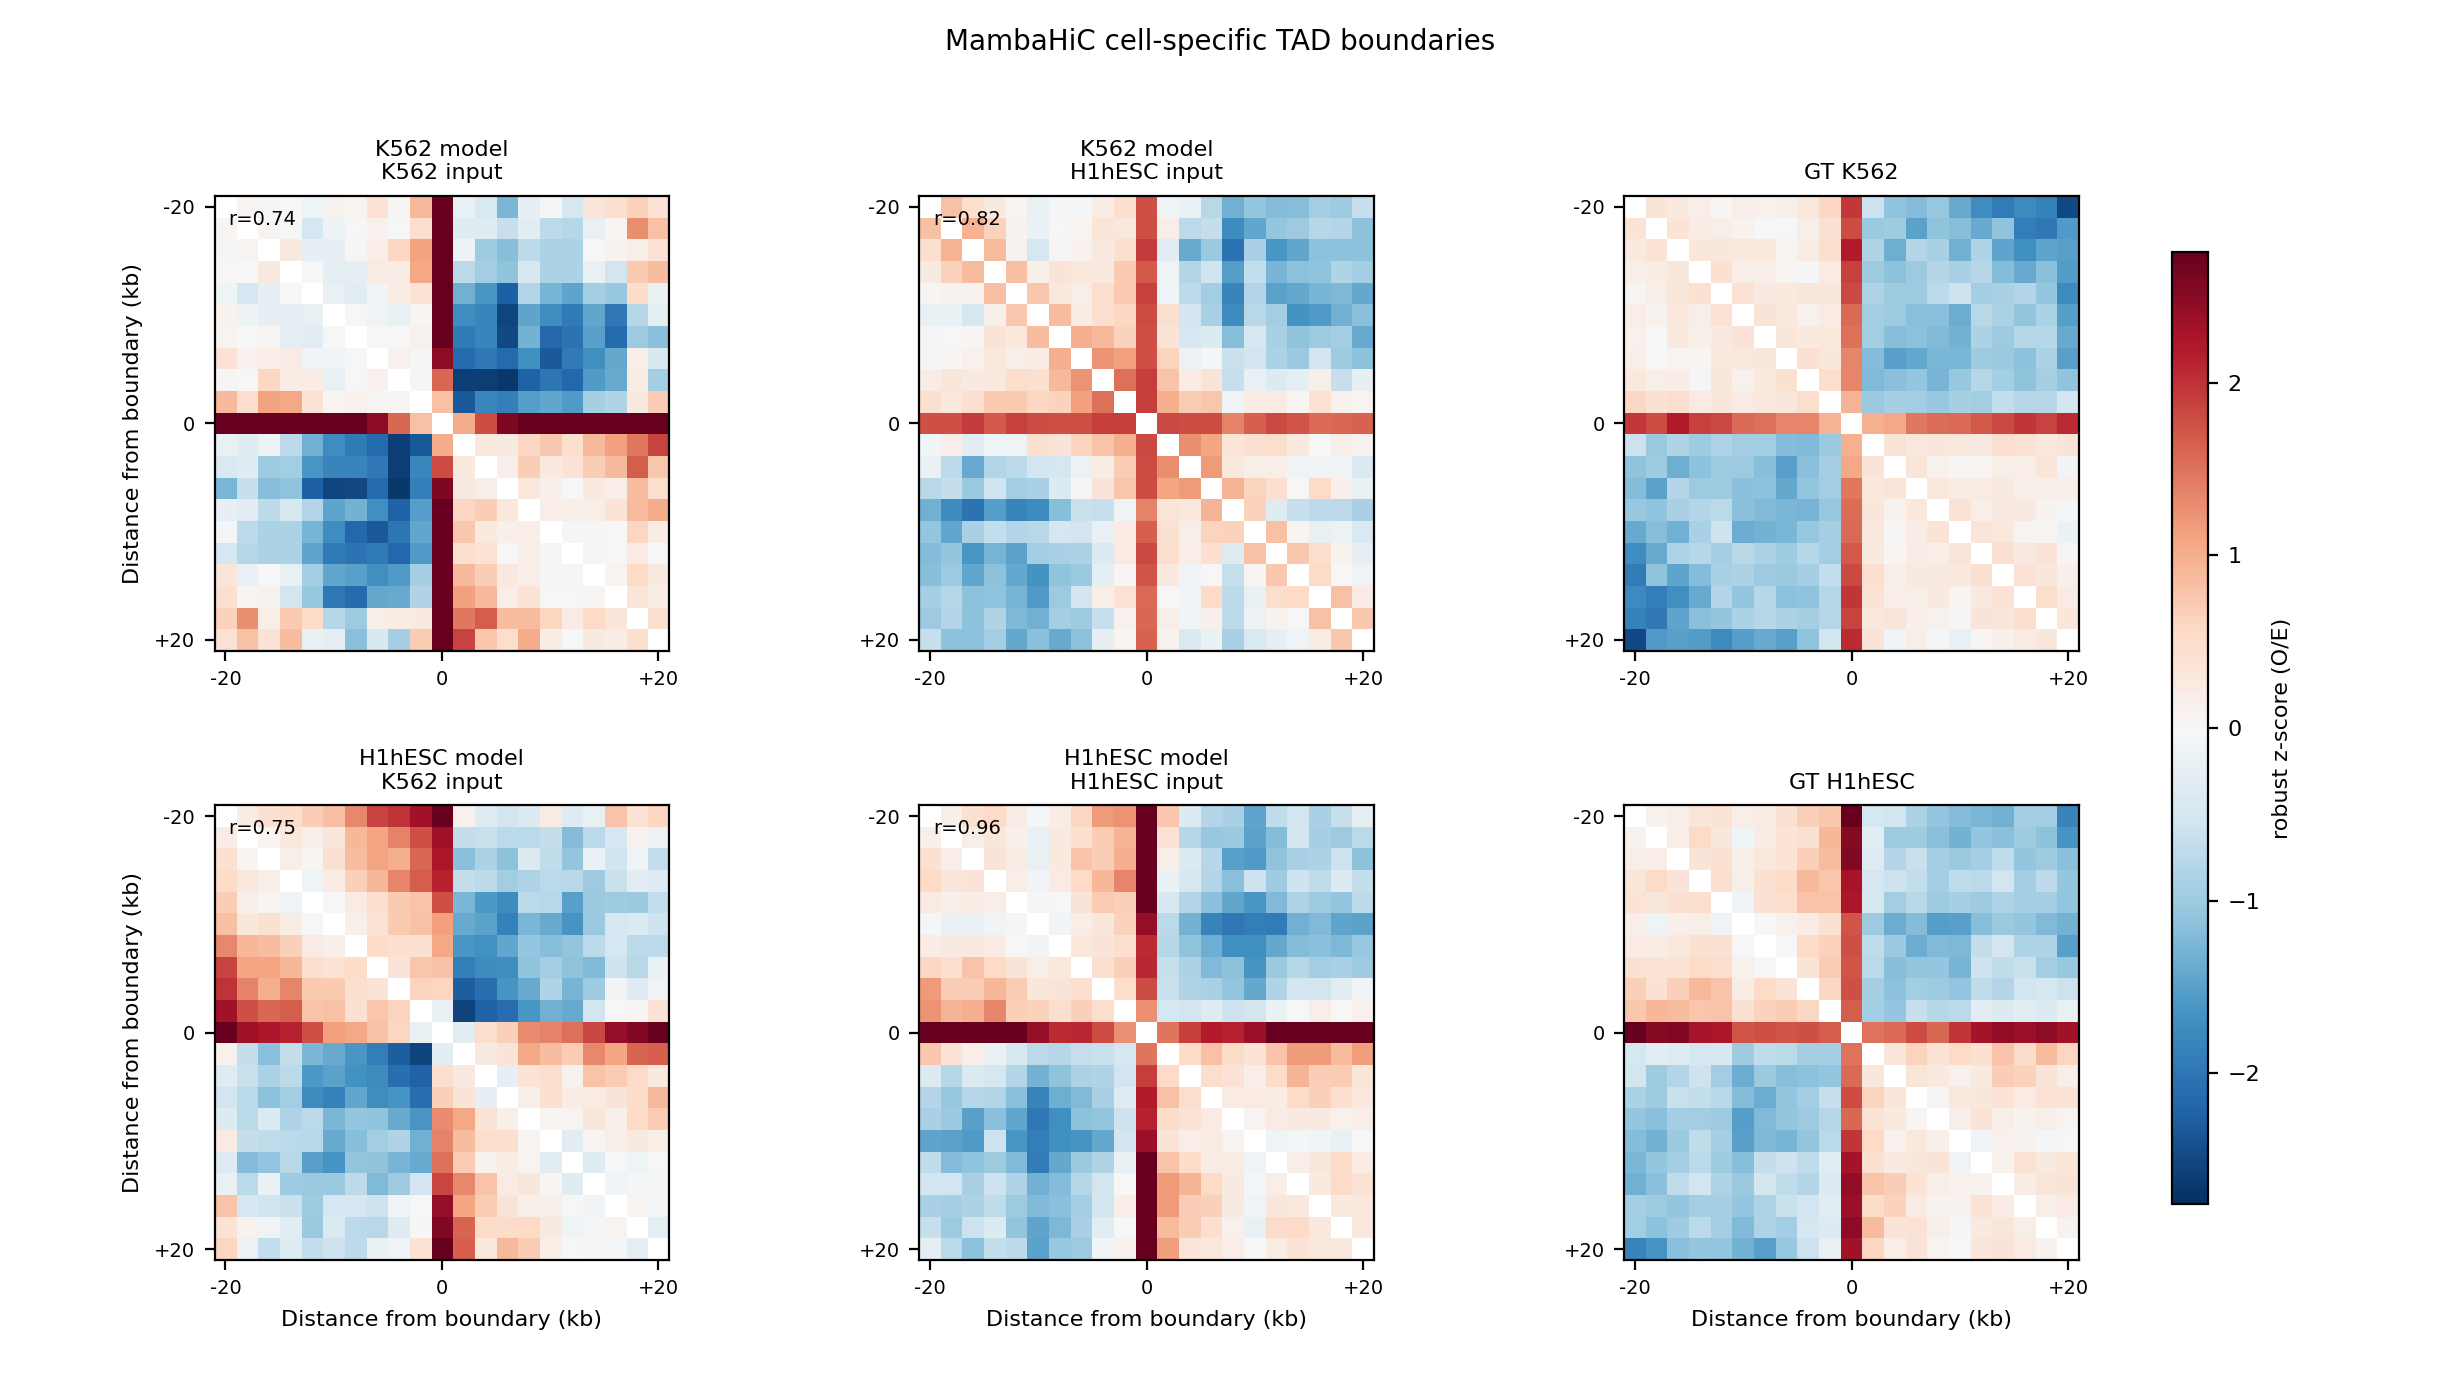

In [9]:
with tempfile.TemporaryDirectory(prefix="mambahic_sup10_mamba_") as temporary:
    temporary = Path(temporary)
    with original_script_environment(temporary):
        mamba_entry = load_original_entry("mamba_predicted_boundary_heatmap.py")
        mamba_entry.main()
    mamba_png = (temporary / "tad_boundary_pileup_MambaHiC.png").read_bytes()
    display(Image(data=mamba_png))


## Baseline cell-specific TAD-boundary heatmaps

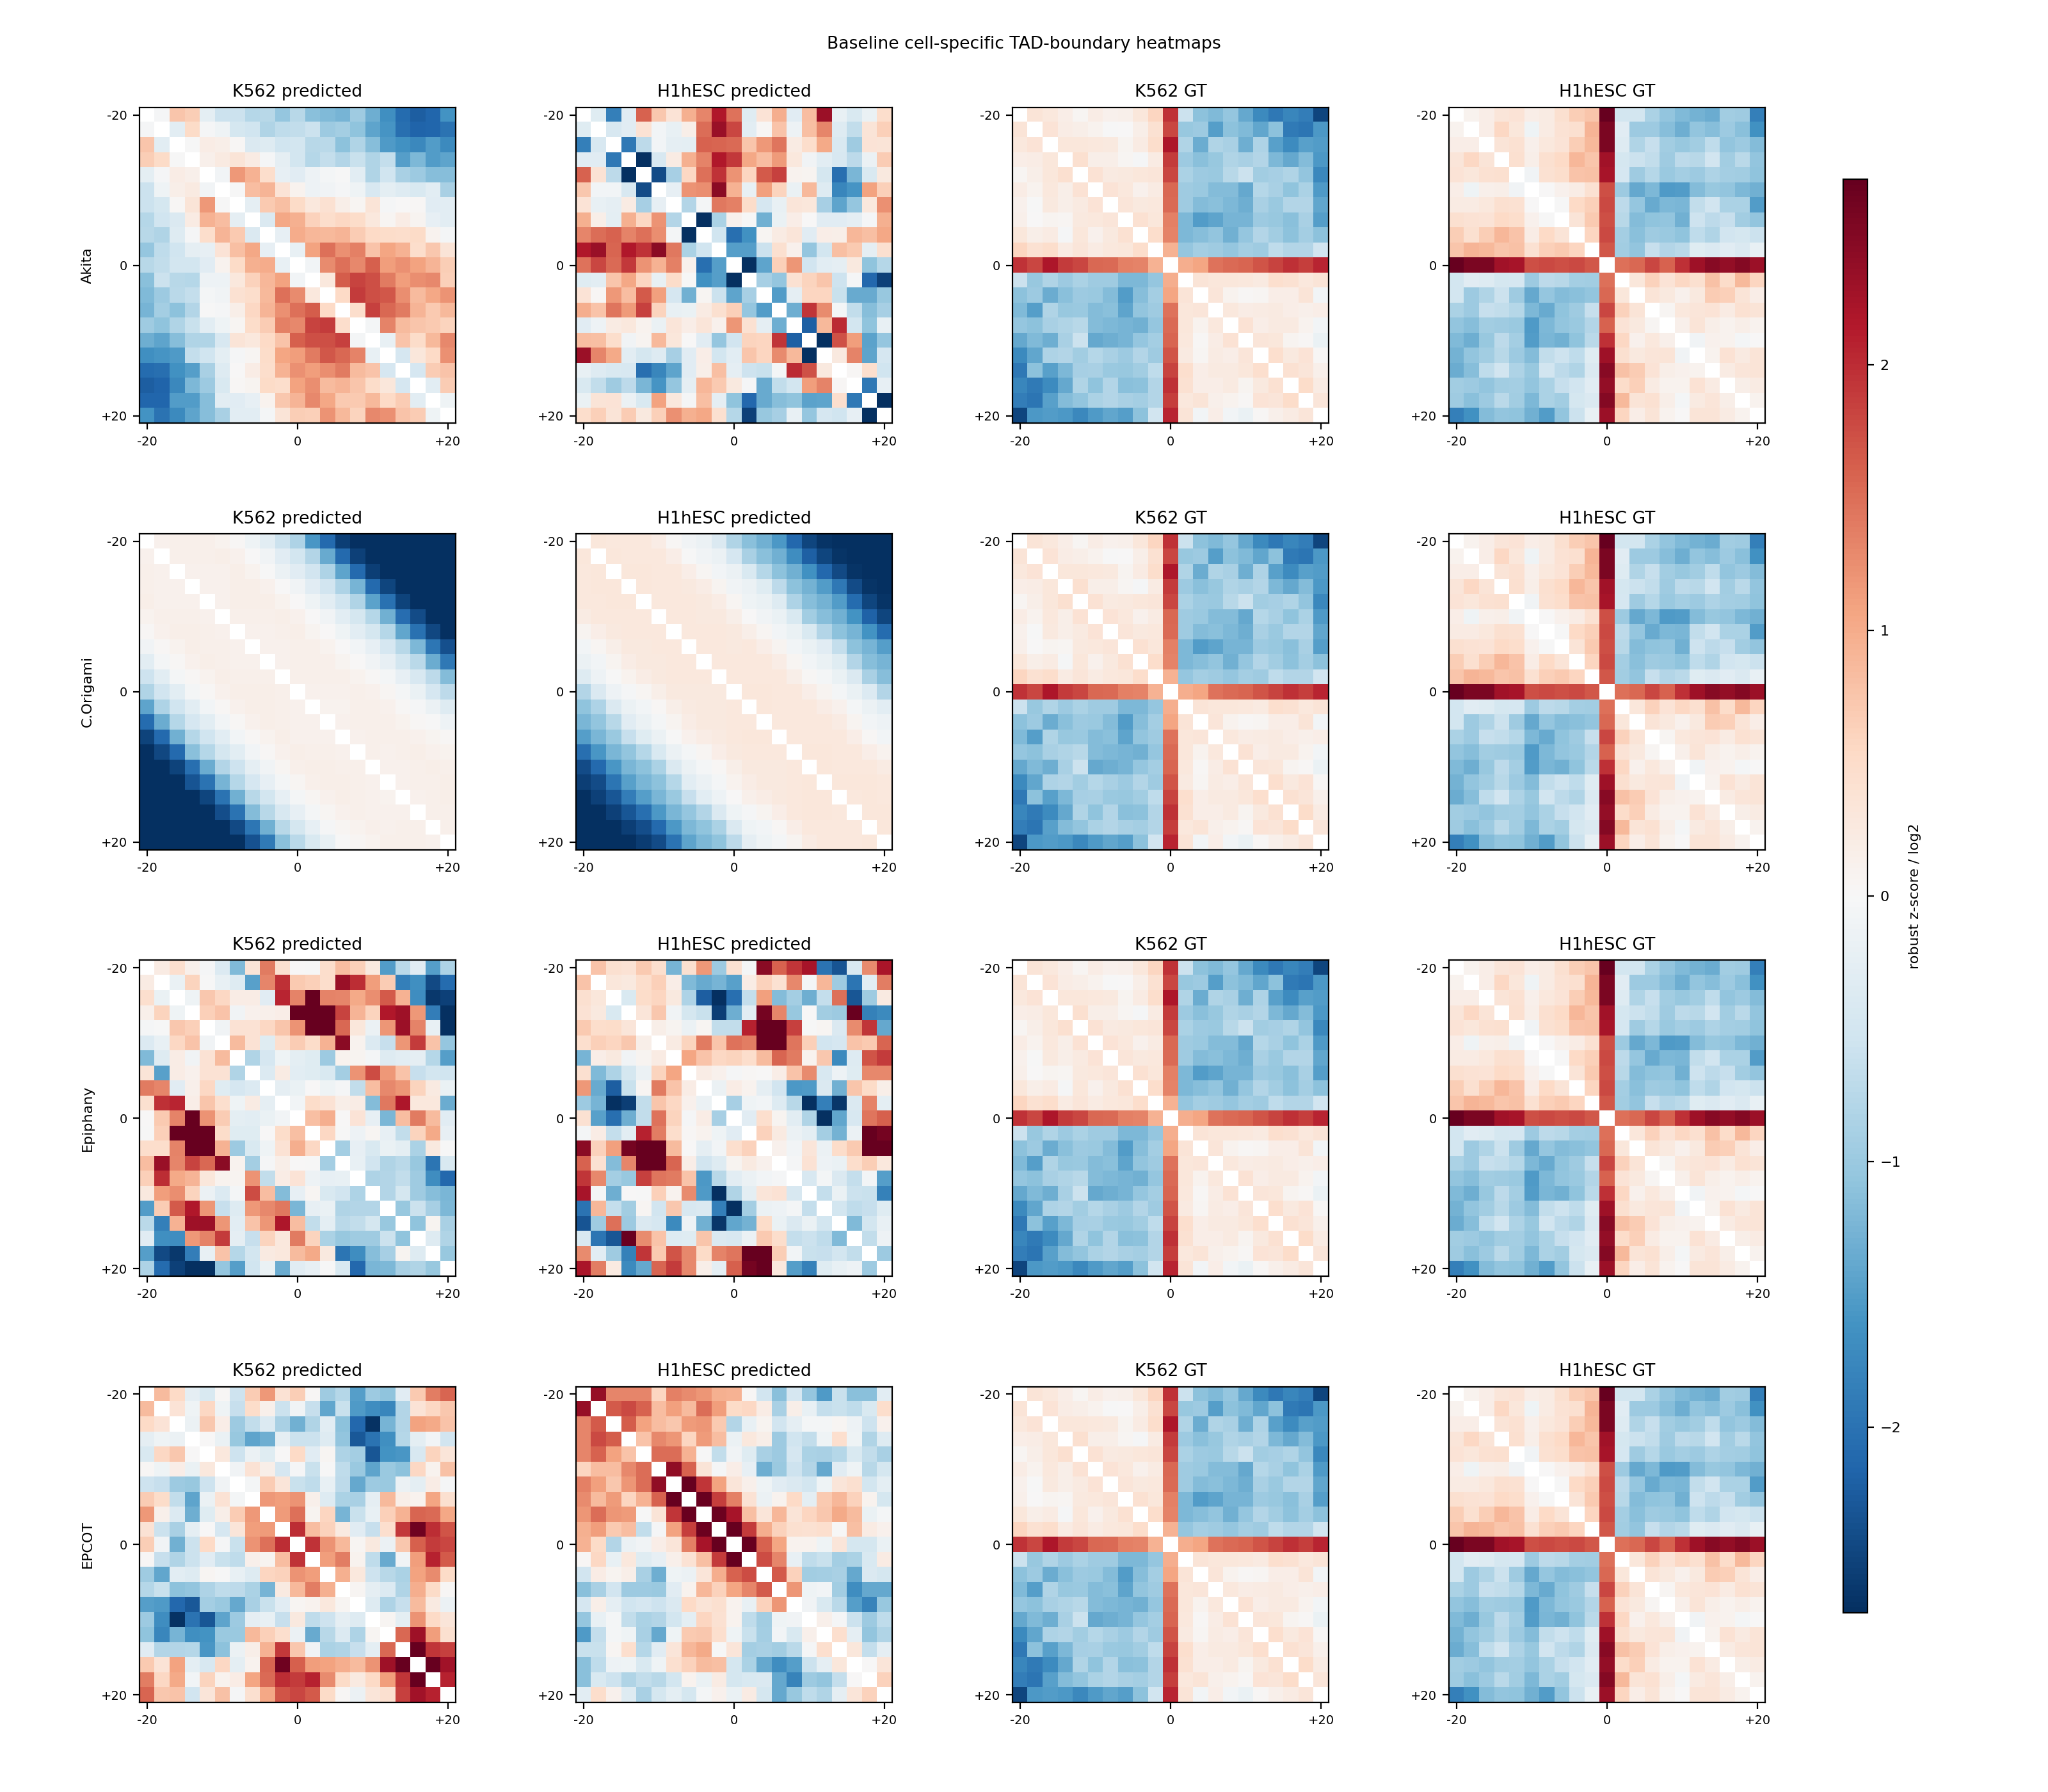

In [10]:
with tempfile.TemporaryDirectory(prefix="mambahic_sup10_baselines_") as temporary:
    temporary = Path(temporary)
    with original_script_environment(temporary):
        baseline_entry = load_original_entry("baseline_boundary_heatmaps.py")
        baseline_entry.main()
    baseline_png = (temporary / "baseline_boundary_heatmaps_combined.png").read_bytes()
    display(Image(data=baseline_png))
